# Genetic content and structure of EGFR ecDNA amplicons (Figure 4)

This notebook contains the analysis behind **Figure 4**. It runs top to bottom and keeps its output, so every panel can be
inspected without running anything.

| Figure 4 panel | What it shows | Part |
|---|---|---|
| A | GBM16: *EGFR* and *CDK4* on the **same** reconstructed ecDNA | 1 |
| B | GBM02: *EGFR* and *CDK4* on **separate** ecDNAs | 1 |
| C | GBM19: non-uniform coverage across the amplicon, with ten superamplified intervals (A-J), tumor and patient-derived cells | 3 |
| D | GBM19: the alignments of one 44-kb HiFi molecule across those intervals | 3 |
| E | Genomic deletion intervals of EGFRvIII / EGFRvII, with the *EGFR* gene model | 2 |
| F | Genomic variant allele fraction (DNA) vs. transcript allele fraction (RNA) of those variants | 2 |

**Part 1: cycle content.** CoRAL reconstructs candidate cyclic amplicons from long-read alignments. Each reconstruction is a set
of genomic segments joined in a particular order and orientation, with an estimated copy number. We draw each cycle as a ring
(segments in cycle order, coloured by chromosome), annotate oncogenes on it, and show the gene content of the underlying
genomic intervals below.

**Part 2: GBM19 superamplified elements.** Normalised coverage across the amplicon in the tumor and in patient-derived cells,
ten narrow intervals with much higher coverage than the surrounding amplicon, and the alignments of one long HiFi read that
passes through many of them repeatedly.

**Part 3: EGFR deletion variants.** Deletion junctions are found from split HiFi reads, clustered, and labelled EGFRvIII
(deletion of exons 2-7) or EGFRvII (exons 14-15). The **genomic** variant allele fraction (gVAF) is the share of molecules
supporting the deletion junction among those supporting it plus continuous wild-type molecules spanning the upstream
breakpoint. The **transcript** allele fraction (TAF) comes from RNA-seq splice junctions: E1->E8 / (E1->E8 + E1->E2) for
EGFRvIII and E13->E16 / (E13->E16 + E13->E14) for EGFRvII.

### Inputs
All files are in `DATA_DIR` (edit the path in the next cell). `UM...` are internal sample identifiers; figure labels (`GBM..`) are
assigned by the `GBM_ID` table.

| File | Produced by |
|---|---|
| `<sample>_amplicon<N>_cycles.txt` | CoRAL (`coral cycle_all`) |
| `gencode.v38.annotation.gtf.gz` | GENCODE v38 gene annotation (hg38) |
| `<sample>_Tumor_chr7_49_59mb.paf.gz` | reads touching chr7:49-59 Mb, re-mapped whole with minimap2 (see Appendix) |
| `PDC_SJ_all.tsv.gz` | RNA-seq splice junctions (STAR `SJ.out.tab`, all samples combined) |
| `rna_sample_map.csv` | maps the RNA-seq sample identifiers to `UM...` identifiers (kept private; not distributed) |
| `UM233_Tumor_chr7_49_59mb_100bp.bed.gz`, `UM233_Cells_chr7_49_59mb_100bp.bed.gz` | mosdepth 100-bp depth, tumor and patient-derived cells |
| `read90311119.sam` | the alignments of the one HiFi read shown in panel F, extracted from the tumor BAM (see Appendix); if absent, the notebook reads them from `UM233_Tumor.bam` |

Requirements: Python with `numpy`, `pandas`, `matplotlib` (and `pysam`, only if the read is read from a BAM instead of the SAM file).

## Setup

In [39]:
import pandas as pd
from pathlib import Path

UM_TO_CARIS = {
    "UM029": "TN23-130603",
    "UM116": "TN23-256130",
    "UM124": "TN24-116062",
    "UM130": "TN24-135404",
    "UM137": "TN24-147430",
    "UM141": "TN23-230312",
    "UM146": "TN24-176631",
    "UM159": "TN24-202882",
    "UM164": "TN24-151349",
    "UM165": "TN24-222438",
    "UM170": "TN24-237771",
    "UM176": "TN24-245925",
    "UM177": "TN24-247504",
    "UM209": "TN25-163080",
    "UM215": "TN25-174506",
    "UM220": "TN25-200167",
    "UM221": "TN25-194848",
    "UM229": "TN25-138999",
    "UM233": "TN25-212151",
    "UM244": "TN25-267805",
    "UM245": "TN25-272934",
    "UM258": "TN25-305072",
}

# Define output directory
DATA_DIR = Path.home() / "Downloads" / "ecDNA"
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Create RNA sample mapping
rna_map_df = pd.DataFrame([
    {"rna_id": caris, "sample": um}
    for um, caris in UM_TO_CARIS.items()
])

# Save CSV
RNA_MAP = DATA_DIR / "rna_sample_map.csv"
rna_map_df.to_csv(RNA_MAP, index=False)

print(f"Saved {len(rna_map_df)} samples to {RNA_MAP}")
display(rna_map_df)

Saved 22 samples to /Users/isaacxu/Downloads/ecDNA/rna_sample_map.csv


,rna_id,sample
0,TN23-130603,UM029
1,TN23-256130,UM116
2,TN24-116062,UM124
3,TN24-135404,UM130
4,TN24-147430,UM137
5,TN23-230312,UM141
6,TN24-176631,UM146
7,TN24-202882,UM159
8,TN24-151349,UM164
9,TN24-222438,UM165


In [40]:
from pathlib import Path
import re, gzip
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
from IPython.display import display

# ---- EDIT: folder holding all input files listed above ------------------------------------
DATA_DIR = Path("/Users/isaacxu/Downloads/")
GTF_PATH = DATA_DIR / "gencode.v38.annotation.gtf.gz"
SJ_TABLE = DATA_DIR / "PDC_SJ_all.tsv.gz"
RNA_MAP  = DATA_DIR / "ecDNA/rna_sample_map.csv"            # columns: rna_id, sample (e.g. UM029)

OUT = Path("fig4_output")                              # figures and tables written here
OUT.mkdir(exist_ok=True)

# Labels used in the figures
GBM_ID = {
    "UM029": "GBM01", "UM116": "GBM02", "UM124": "GBM03", "UM130": "GBM04", "UM137": "GBM05",
    "UM141": "GBM06", "UM146": "GBM07", "UM159": "GBM08", "UM164": "GBM09", "UM165": "GBM10",
    "UM170": "GBM11", "UM176": "GBM12", "UM177": "GBM13", "UM209": "GBM14", "UM215": "GBM15",
    "UM220": "GBM16", "UM221": "GBM17", "UM229": "GBM18", "UM233": "GBM19", "UM244": "GBM20",
    "UM245": "GBM21", "UM258": "GBM22",
}

# Tumors left out of the EGFR variant analysis
EXCLUDE_UM = {"UM141"}        # GBM06

def um_id(name):
    """'UM29', 'UM029' or 'UM29_Cells' -> 'UM029'"""
    number = int(re.search(r"UM0*(\d+)", name).group(1))
    return f"UM{number:03d}"

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 9})

# Part 1. Cycle content: *EGFR* and *CDK4* on the same or on separate ecDNAs (Figure 4A, B)

The plotting code below draws a CoRAL cycle as a ring. Segments that are adjacent on the same chromosome and strand
(within `merge_gap` bp) are merged and drawn as one arc; arc length is proportional to genomic size. Gene models from the
GENCODE annotation are drawn on the ring for the genes listed in `annotate_genes`, and the genomic footprint of the cycle
(one panel per contiguous region) is drawn underneath for the genes in `footprint_genes`.

### 1.1 Plotting library

The functions below parse the GENCODE annotation and CoRAL cycle files, merge and colour segments, and draw the ring and the gene-footprint panels. They are collapsed into sections for readability; they must all be run.

In [41]:
import re, gzip, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.backends.backend_pdf import PdfPages
from collections import defaultdict

# ═══════════════════════════════════════════════════════════════════════════
# SECTION 1 — GTF parser
# ═══════════════════════════════════════════════════════════════════════════
def parse_gtf_to_gene_db(gtf_path, gene_types=("protein_coding",)):
    opener = gzip.open if gtf_path.endswith(".gz") else open
    gene_rows, tx_exons, tx_gene, tx_is_mane = {}, defaultdict(list), {}, set()
    with opener(gtf_path, "rt") as fh:
        for line in fh:
            if line.startswith("#"): continue
            parts = line.rstrip("\n").split("\t")
            if len(parts) < 9: continue
            feature = parts[2]
            if feature not in ("gene","transcript","exon"): continue
            chrom, start, end, strand, attrs = (parts[0], int(parts[3])-1,
                int(parts[4]), parts[6], parts[8])
            def _a(k):
                m = re.search(rf'{k} "([^"]+)"', attrs)
                return m.group(1) if m else None
            gname = _a("gene_name"); gtype = _a("gene_type") or _a("gene_biotype")
            if not gname or (gene_types and gtype not in gene_types): continue
            if feature == "gene":
                gene_rows[gname] = dict(gene_name=gname, chrom=chrom,
                    gene_start=start, gene_end=end, strand=strand, gene_type=gtype)
            elif feature == "transcript":
                tid = _a("transcript_id")
                if tid: tx_gene[tid] = gname; tx_is_mane.add(tid) if "MANE_Select" in attrs else None
            elif feature == "exon":
                tid = _a("transcript_id")
                if tid: tx_gene[tid] = gname; tx_exons[tid].append((start, end))
    gene_tx = defaultdict(list)
    for tid, gn in tx_gene.items():
        if tid in tx_exons: gene_tx[gn].append(tid)
    exon_dict = {}
    for gn, tids in gene_tx.items():
        mane = [t for t in tids if t in tx_is_mane]
        cands = mane if mane else tids
        best = max(cands, key=lambda t: (len(tx_exons[t]),
            max(e for _,e in tx_exons[t]) - min(s for s,_ in tx_exons[t])))
        exon_dict[gn] = sorted(set(tx_exons[best]))
    return pd.DataFrame(gene_rows.values()).reset_index(drop=True), exon_dict

def _ci(x): return int(str(x).replace(",","").strip())

def build_features(raw_list, chrom):
    out = []
    for ftype, name, a, b in raw_list:
        s, e = _ci(a), _ci(b)
        if s > e: s, e = e, s
        out.append((ftype, name, chrom, s-1, e))
    return out

def get_gene_features(gene_name, gene_df, exon_dict, color=None):
    DEFAULT_COLORS = ["navy","darkgreen","saddlebrown","purple","darkred",
        "darkcyan","olive","indigo","teal","chocolate","crimson","steelblue"]
    row = gene_df[gene_df["gene_name"] == gene_name]
    if row.empty: raise ValueError(f"Gene '{gene_name}' not found")
    row = row.iloc[0]
    chrom, gstart, gend = row["chrom"], row["gene_start"], row["gene_end"]
    exs = sorted(exon_dict.get(gene_name, []))
    if not exs: exs = [(gstart, gend)]
    raw = [("exon", f"E{i+1}", str(es+1), str(ee)) for i,(es,ee) in enumerate(exs)]
    col = color or DEFAULT_COLORS[abs(hash(gene_name)) % len(DEFAULT_COLORS)]
    return (chrom, gstart, gend, raw, col)

def build_gene_db(gene_names, gene_df, exon_dict, color_map=None):
    db = {}
    for gn in gene_names:
        try: db[gn] = get_gene_features(gn, gene_df, exon_dict,
                                         color=color_map.get(gn) if color_map else None)
        except ValueError as e: print(f"  [warn] {e}")
    return db

In [42]:
# ═══════════════════════════════════════════════════════════════════════════
# SECTION 2 — Cancer gene tiers
# ═══════════════════════════════════════════════════════════════════════════
CANCER_GENES_TIER1 = {
    "EGFR","ERBB2","ERBB3","ERBB4","MET","FGFR1","FGFR2","FGFR3","FGFR4",
    "KIT","PDGFRA","PDGFRB","RET","ALK","ROS1","NTRK1","NTRK2","NTRK3",
    "CDK4","CDK6","CCND1","CCND2","CCND3","CCNE1","RB1","CDKN2A","CDKN2B",
    "MYC","MYCN","MYCL","MDM2","MDM4","TP53",
    "PIK3CA","PIK3CB","AKT1","AKT2","AKT3","PTEN","MTOR","TSC1","TSC2",
    "KRAS","NRAS","HRAS","BRAF","RAF1","MAP2K1","MAP2K2",
    "GLI1","GLI2","GLI3","TERT","AR","ESR1","MYB","MITF","SOX2",
    "YAP1","WWTR1","EZH2","ARID1A","SMARCA4","BRCA1","BRCA2","ATM",
    "VEGFA","FRS2","CPM","DDIT3","HMGA2","SEC61G","LANCL2","SEPT14",
    "PDCD1LG2","CD274","PSPH","SOX9","ELAVL2",
}

def auto_gene_db(merged_arcs, gene_df, exon_dict, color_map=None):
    """
    Find ALL genes overlapping merged_arcs.
    Tier 1 cancer genes are sorted first so they get lane priority in layout.
    Returns (gene_db, label_genes, tier1_genes).
    """
    GENE_PALETTE = (list(plt.cm.tab10.colors) + list(plt.cm.Dark2.colors)
                    + list(plt.cm.Set1.colors))

    chrom_gene_rows = defaultdict(list)
    seen = set()
    for _, _, ch, ms, me in merged_arcs:
        hits = gene_df[
            (gene_df["chrom"] == ch) &
            (gene_df["gene_start"] < me) &
            (gene_df["gene_end"]   > ms)
        ][["gene_name","chrom","gene_start","gene_end"]].itertuples(index=False)
        for h in hits:
            if h.gene_name not in seen:
                seen.add(h.gene_name)
                chrom_gene_rows[ch].append(h)

    all_names, label_genes, tier1_genes = [], set(), set()
    color_idx = 0
    auto_colors = {}

    for ch, genes in chrom_gene_rows.items():
        # sort Tier 1 first, then by genomic start position
        genes_sorted = sorted(
            genes,
            key=lambda h: (
                0 if h.gene_name in CANCER_GENES_TIER1 else 1,
                h.gene_start
            )
        )
        names = [g.gene_name for g in genes_sorted]
        all_names.extend(names)
        for n in names:
            if color_map and n in color_map:
                auto_colors[n] = color_map[n]
            else:
                auto_colors[n] = GENE_PALETTE[color_idx % len(GENE_PALETTE)]
                color_idx += 1
        label_genes.update(names)
        tier1_genes.update(n for n in names if n in CANCER_GENES_TIER1)

    all_names = list(dict.fromkeys(all_names))
    merged_color_map = {
        n: auto_colors.get(n, (color_map or {}).get(n))
        for n in all_names
    }
    gene_db = build_gene_db(all_names, gene_df, exon_dict, color_map=merged_color_map)
    return gene_db, label_genes, tier1_genes

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# SECTION 3 — Cycle parser
# ═══════════════════════════════════════════════════════════════════════════
def parse_cycles_txt(path):
    seg, cycles = {}, {}
    with open(path) as fh:
        for line in fh:
            line = line.rstrip()
            if line.startswith("Segment\t"):
                p = line.split("\t")
                seg[int(p[1])] = (p[2], int(p[3]), int(p[4]))
            elif line.startswith("Cycle=") or line.startswith("Path="):
                is_cyc = line.startswith("Cycle=")
                m = re.match(r'(?:Cycle|Path)=(\d+);Copy_count=([\d.]+);Segments=([^;]+)', line)
                if not m: continue
                cid, cc = int(m.group(1)), float(m.group(2))
                order = [(int(t[:-1]), t[-1]) for t in m.group(3).split(",")
                         if t.strip() not in ("0+","0-")]
                cycles[cid] = {"is_cycle": is_cyc, "copy_count": cc, "segments": order}
    return seg, cycles

In [43]:
# ═══════════════════════════════════════════════════════════════════════════
# SECTION 4 — Segment merging & colors
# ═══════════════════════════════════════════════════════════════════════════
def merge_visual_segments(seg, order, merge_gap=50):
    if not order: return [], {}
    groups = [0]; g = 0
    for i in range(1, len(order)):
        sp, stp = order[i-1]; sc_id, stc = order[i]
        cp, sp_s, sp_e = seg[sp]; cc2, sc_s, sc_e = seg[sc_id]
        if cp != cc2 or stp != stc:
            contiguous = False
        elif stp == '+':
            contiguous = 0 <= sc_s - sp_e - 1 <= merge_gap
        else:
            contiguous = 0 <= sp_s - sc_e - 1 <= merge_gap
        if not contiguous: g += 1
        groups.append(g)
    group_info = {}
    for i, (sid, _) in enumerate(order):
        gid = groups[i]; ch, s, e = seg[sid]
        if gid not in group_info: group_info[gid] = [ch, s, e]
        else:
            group_info[gid][1] = min(group_info[gid][1], s)
            group_info[gid][2] = max(group_info[gid][2], e)
    return groups, {k: tuple(v) for k, v in group_info.items()}

def merge_segments(seg, order, merge_gap=50):
    """
    Merge consecutive compatible segments into visual groups.
    Returns:
        group_ids  : list[int] len=len(order), e.g. [0,1,2,3,4,5,5,5,6]
        group_info : dict {gid -> (chrom, merged_start, merged_end)}
    """
    if not order:
        return [], {}

    group_ids = [0]
    g = 0
    for i in range(1, len(order)):
        sp, stp = order[i-1]
        sc, stc = order[i]
        cp, sp_s, sp_e = seg[sp]
        cc2, sc_s, sc_e = seg[sc]
        if cp != cc2 or stp != stc:
            contiguous = False
        elif stp == '+':
            contiguous = 0 <= sc_s - sp_e - 1 <= merge_gap
        else:
            contiguous = 0 <= sp_s - sc_e - 1 <= merge_gap
        if not contiguous:
            g += 1
        group_ids.append(g)

    group_info = {}
    for i, (sid, _) in enumerate(order):
        gid = group_ids[i]
        ch, s, e = seg[sid]
        if gid not in group_info:
            group_info[gid] = [ch, s, e]
        else:
            group_info[gid][1] = min(group_info[gid][1], s)
            group_info[gid][2] = max(group_info[gid][2], e)
    group_info = {k: tuple(v) for k, v in group_info.items()}
    return group_ids, group_info

def assign_colors(seg, order, merge_gap=50):
    groups, group_info = merge_visual_segments(seg, order, merge_gap)
    seen_g = set(); ordered_groups = []
    for i, (sid, _) in enumerate(order):
        gid = groups[i]
        if gid not in seen_g:
            seen_g.add(gid); ordered_groups.append((gid, group_info[gid]))
    chrom_order = []
    for _, (ch, ms, me) in ordered_groups:
        if ch not in chrom_order: chrom_order.append(ch)
    QUAL_SETS = [list(plt.cm.tab20c.colors), list(plt.cm.tab20b.colors),
                 list(plt.cm.tab20.colors),  list(plt.cm.Dark2.colors),
                 list(plt.cm.Paired.colors)]
    chrom_palette = {ch: QUAL_SETS[ci % len(QUAL_SETS)] for ci,ch in enumerate(chrom_order)}
    chrom_idx = defaultdict(int)
    interval_color = {}; group2color = {}
    for gid, (ch, ms, me) in ordered_groups:
        key = (ch, ms, me)
        if key not in interval_color:
            palette = chrom_palette[ch]
            interval_color[key] = palette[chrom_idx[ch] % len(palette)]
            chrom_idx[ch] += 1
        group2color[gid] = interval_color[key]
    sid2color = {sid: group2color[groups[i]] for i,(sid,_) in enumerate(order)}
    return sid2color, groups, group_info

In [44]:
# ═══════════════════════════════════════════════════════════════════════════
# SECTION 5 — Arc geometry
# ═══════════════════════════════════════════════════════════════════════════
def _safe_trim(a, b, pad):
    w = b-a
    if w <= 0: return None
    return (a,b) if 2*pad >= w else (a+pad, b-pad)

def _enforce_min_w(a, b, min_w):
    if b-a >= min_w: return a, b
    mid = 0.5*(a+b); return mid-0.5*min_w, mid+0.5*min_w

def _merge_arcs(arcs):
    if not arcs: return []
    arcs = sorted(arcs); merged = [list(arcs[0])]
    for a, b in arcs[1:]:
        if a <= merged[-1][1]: merged[-1][1] = max(merged[-1][1], b)
        else: merged.append([a, b])
    return [(a,b) for a,b in merged]

def interval_to_arcs_merged(merged_arcs, ang_edges, chrom, start, end):
    chunks = []
    for i, (_,_,mch,ms,me) in enumerate(merged_arcs):
        if mch != chrom: continue
        os, oe = max(ms,start), min(me,end)
        if oe <= os: continue
        denom = me-ms
        if denom <= 0: continue
        f0, f1 = (os-ms)/denom, (oe-ms)/denom
        t0, t1 = ang_edges[i], ang_edges[i+1]
        ta, tb = t0+(t1-t0)*f0, t0+(t1-t0)*f1
        if tb < ta: ta, tb = tb, ta
        chunks.append((ta, tb))
    return chunks

def draw_gene_ring(ax, merged_arcs, ang_edges, features,
                   bottom, exon_h=0.06, intron_lw=1.5,
                   arc_pad=0.006, min_exon_rad=0.004, color="navy", alpha=0.92):
    chrom  = features[0][2]
    gstart = min(s for *_,s,e in features)
    gend   = max(e for *_,s,e in features)
    span = [_safe_trim(a,b,arc_pad)
            for a,b in interval_to_arcs_merged(merged_arcs,ang_edges,chrom,gstart,gend)]
    span = [x for x in span if x]
    for a,b in _merge_arcs(span):
        th = np.linspace(a,b,400)
        ax.plot(th, np.full_like(th, bottom+exon_h*0.5),
                lw=intron_lw, color=color, alpha=alpha,
                solid_capstyle="round", zorder=29)
    for ftype,name,fchrom,fs,fe in features:
        if ftype != "exon": continue
        for a,b in interval_to_arcs_merged(merged_arcs,ang_edges,fchrom,fs,fe):
            ab = _safe_trim(a,b,arc_pad)
            if ab is None: continue
            a,b = _enforce_min_w(*ab, min_exon_rad)
            ax.bar(a, exon_h, width=(b-a), bottom=bottom, align="edge",
                   facecolor=color, edgecolor="none", linewidth=0,
                   alpha=alpha, zorder=30)

In [45]:
# ═══════════════════════════════════════════════════════════════════════════
# SECTION 6 — Donut gene annotation
# ═══════════════════════════════════════════════════════════════════════════
def annotate_genes_on_donut(ax, gene_db, merged_arcs, ang,
                             annotate_genes, inner_r, ring_h,
                             label_r_offset=0.22, fontsize=11):
    """
    Draw bold gene name labels on the donut for specified genes.
    - Always upright (no flipping)
    - Tangentially rotated so text runs along the circle
    - Bottom-half labels are flipped so letters face outward
    """
    label_r = inner_r + ring_h + label_r_offset
    for gname in annotate_genes:
        if gname not in gene_db: continue
        gchrom, gstart, gend, feat_raw, gcol = gene_db[gname]
        spans = interval_to_arcs_merged(merged_arcs, ang, gchrom, gstart, gend)
        if not spans: continue
        widest = max(spans, key=lambda x: x[1]-x[0])
        theta_mid = 0.5*(widest[0]+widest[1])

        # normalise to [0, 2π]
        theta_norm = theta_mid % (2*np.pi)

        # tangent rotation in display degrees
        # polar axes: N=0, clockwise. Convert to mathplotlib display angle.
        # display_angle = 90 - degrees(theta) for clockwise-from-north
        rot_deg = 90 - np.degrees(theta_mid)

        # bottom half (theta_norm in (π, 2π) i.e. left+bottom of clock):
        # flip 180° so letters always read outward, never upside-down
        if np.pi < theta_norm < 2*np.pi:
            rot_deg += 180

        ax.text(theta_mid, label_r, gname,
                ha="center", va="center",
                fontsize=fontsize, fontweight="bold",
                color=gcol, rotation=rot_deg,
                rotation_mode="anchor", zorder=40)

In [46]:
# ═══════════════════════════════════════════════════════════════════════════
# SECTION 7 — Footprint layout (UCSC-style gene tracks)
# ═══════════════════════════════════════════════════════════════════════════
def _chrom_key(ch):
    m = re.search(r"(\d+|X|Y)$", ch)
    if not m: return (999,ch)
    v = m.group(1)
    return (int(v) if v.isdigit() else (23 if v=="X" else 24), ch)

def build_footprint_panels(unique_groups, max_internal_gap=1_000_000):
    chrom_segs = defaultdict(list)
    for ch, ms, me, gid in unique_groups:
        chrom_segs[ch].append((ms, me))
    panels = []
    for ch in sorted(chrom_segs, key=_chrom_key):
        segs = sorted(chrom_segs[ch])
        regions = [[segs[0][0], segs[0][1]]]
        for s,e in segs[1:]:
            if s - regions[-1][1] <= max_internal_gap: regions[-1][1] = max(regions[-1][1], e)
            else: regions.append([s,e])
        for r in regions: panels.append((ch, r[0], r[1]))
    return panels

def _ucsc_gene_layout(genes_in_panel, r2v, pi, label_genes, char_width_virt=9_000):
    lane_state = []  # (body_end, label_end) per lane
    result = []
    for gname, gchrom, gc_s, gc_e, gcol in genes_in_panel:
        vx_body_start = r2v(gchrom, gc_s, pi)
        vx_body_end   = r2v(gchrom, gc_e, pi)
        labeled       = gname in label_genes
        label_w       = len(gname) * char_width_virt if labeled else 0
        vx_label_left = vx_body_start - label_w
        placed = False
        for li, (body_end, label_end) in enumerate(lane_state):
            body_fits  = vx_label_left >= body_end
            label_fits = vx_body_start >= label_end
            if body_fits and label_fits:
                lane_state[li] = (vx_body_end, vx_body_start)
                result.append((gname, gchrom, gc_s, gc_e, gcol, li, labeled))
                placed = True; break
            elif vx_body_start >= body_end and vx_body_start >= label_end:
                lane_state[li] = (vx_body_end, label_end)
                result.append((gname, gchrom, gc_s, gc_e, gcol, li, False))
                placed = True; break
        if not placed:
            lane_state.append((vx_body_end, vx_body_start))
            result.append((gname, gchrom, gc_s, gc_e, gcol, len(lane_state)-1, labeled))
    return result

# ─────────────────────────────────────────────────────────────────────────────
# REVISED draw_footprint — replace your existing function with this one.
# Changes vs original:
#   - edgecolors removed from segment bars (req 1)
#   - seg_h smaller default 0.18 -> 0.10 (req 3); frees vertical space
#   - min_seg_frac: minimum segment display width as fraction of panel span,
#     so tiny segments stay visible (req 4)
#   - exon_h bumped 0.07 -> 0.10 and GENE_LANE_H more generous (req 5)
#   - tick_gap param controls distance between exon lanes and tick row (req 6)
# ─────────────────────────────────────────────────────────────────────────────
def draw_footprint(ax, panels, unique_groups, gid2color, gene_db,
                   label_genes=None, flank=75_000,
                   exon_h=0.10, seg_h=0.10, lane_gap=0.025,
                   min_exon_bp=300, max_gene_lanes=6,
                   min_seg_frac=0.012,      # NEW: min segment width = 1.2% of panel
                   tick_gap=0.06,           # NEW: gap between exons and tick row
                   gene_lane_extra=0.06):   # NEW: vertical room per gene lane
    if label_genes is None:
        label_genes = set(gene_db.keys())
    panel_windows = [(ch, rs-flank, re+flank) for ch,rs,re in panels]
    total_bp  = sum(we-ws for _,ws,we in panel_windows)
    inter_gap = total_bp * 0.06 if len(panel_windows) > 1 else 0
    panel_offsets = []; cursor = 0.0
    for _,ws,we in panel_windows:
        panel_offsets.append(cursor - ws)
        cursor += (we-ws) + inter_gap
    total_virt = cursor - inter_gap
    def r2v(ch, pos, pi):
        return pos + panel_offsets[pi]
    def find_panel(ch, pos):
        for pi,(pch,ws,we) in enumerate(panel_windows):
            if pch==ch and ws<=pos<=we: return pi
        return None
    # panel span lookup for min-sliver sizing
    panel_span = {pi: (we-ws) for pi,(_,ws,we) in enumerate(panel_windows)}

    # greedy lane stacking for segment bars
    chrom_lane_ends = defaultdict(list)
    gid_lane = {}; gid_panel = {}
    for ch,ms,me,gid in unique_groups:
        pi = find_panel(ch, ms)
        if pi is None: continue
        gid_panel[gid] = pi; key = (ch,pi)
        ends = chrom_lane_ends[key]; placed = False
        for li,end in enumerate(ends):
            if ms >= end:
                ends[li] = me; gid_lane[gid] = li
                placed = True; break
        if not placed:
            gid_lane[gid] = len(ends); ends.append(me)
    max_lanes = max((len(v) for v in chrom_lane_ends.values()), default=1)
    total_bar_h = max_lanes * (seg_h + lane_gap)

    # ── segment bars (NO edgecolor; minimum display width) ──────────────────
    for ch,ms,me,gid in unique_groups:
        pi = gid_panel.get(gid)
        if pi is None: continue
        y0 = gid_lane[gid] * (seg_h + lane_gap)
        seg_w = me - ms
        min_w = panel_span[pi] * min_seg_frac
        if seg_w < min_w:                      # widen tiny segments, keep centered
            mid = (ms + me) / 2
            draw_ms = mid - min_w/2
            draw_w  = min_w
        else:
            draw_ms = ms
            draw_w  = seg_w
        ax.broken_barh(
            [(r2v(ch,draw_ms,pi), draw_w)], (y0, seg_h),
            facecolors=[gid2color[gid]],
            edgecolors="none", linewidth=0, zorder=5      # req 1
        )

    # ── gene track ──────────────────────────────────────────────────────────
    GENE_LANE_H = exon_h + gene_lane_extra
    gene_base_y = -(lane_gap + exon_h + 0.04)
    feats_by_gene = {
        gname: build_features(feat_raw, gchrom)
        for gname,(gchrom,gstart,gend,feat_raw,gcol) in gene_db.items()
    }
    actual_max_lanes = 0
    for pi,(ch,ws,we) in enumerate(panel_windows):
        panel_width_bp = we - ws
        min_exon_bp_panel = max(min_exon_bp, panel_width_bp * 0.004)
        panel_genes = sorted([
            (gname, gchrom, max(gstart,ws), min(gend,we), gcol)
            for gname,(gchrom,gstart,gend,feat_raw,gcol) in gene_db.items()
            if gchrom==ch and gend>=ws and gstart<=we
        ], key=lambda x: x[2])
        if not panel_genes: continue
        CHAR_W = panel_width_bp * 0.012
        lane_body_ends  = []
        lane_label_ends = []
        laid_out = []
        for gname, gchrom, gc_s, gc_e, gcol in panel_genes:
            vx0 = r2v(gchrom, gc_s, pi)
            vx1 = r2v(gchrom, gc_e, pi)
            if vx1 <= vx0: continue
            in_label_genes = gname in label_genes
            label_w = len(gname) * CHAR_W if in_label_genes else 0
            placed = False
            for li in range(min(len(lane_body_ends), max_gene_lanes)):
                body_clear  = vx0 >= lane_body_ends[li]
                label_left  = vx0 - label_w * 0.5
                label_right = vx1 + label_w * 0.5
                label_clear = label_left >= lane_label_ends[li]
                if body_clear and label_clear:
                    lane_body_ends[li]  = vx1
                    lane_label_ends[li] = label_right
                    laid_out.append((gname, gchrom, gc_s, gc_e,
                                     gcol, li, in_label_genes))
                    placed = True; break
            if not placed and len(lane_body_ends) < max_gene_lanes:
                lane_body_ends.append(vx1)
                label_right = vx1 + (len(gname) * CHAR_W * 0.5
                                     if in_label_genes else 0)
                lane_label_ends.append(label_right)
                laid_out.append((gname, gchrom, gc_s, gc_e,
                                 gcol, len(lane_body_ends)-1, in_label_genes))
        actual_max_lanes = max(
            actual_max_lanes,
            max((x[5] for x in laid_out), default=-1) + 1
        )
        for gname, gchrom, gc_s, gc_e, gcol, lane, labeled in laid_out:
            gy       = gene_base_y - lane * GENE_LANE_H
            intron_y = gy + exon_h * 0.5
            ax.hlines(intron_y,
                      r2v(gchrom, gc_s, pi),
                      r2v(gchrom, gc_e, pi),
                      lw=1.5, color=gcol, alpha=0.9, zorder=6)
            for ftype,fname,fch,fs,fe in feats_by_gene[gname]:
                if ftype != "exon" or fch != gchrom: continue
                os = max(fs, ws); oe = min(fe, we)
                if oe <= os: continue
                width_bp = max(oe - os, min_exon_bp_panel)
                mid_bp   = (os + oe) / 2
                draw_s   = mid_bp - width_bp/2
                draw_e   = mid_bp + width_bp/2
                ax.broken_barh(
                    [(r2v(gchrom, draw_s, pi),
                      r2v(gchrom, draw_e, pi) - r2v(gchrom, draw_s, pi))],
                    (gy, exon_h),
                    facecolors=[gcol], edgecolors="none",
                    linewidth=0, zorder=7
                )
            if labeled:
                label_x = (r2v(gchrom, gc_s, pi) + r2v(gchrom, gc_e, pi)) / 2
                ax.text(
                    label_x, gy + exon_h + 0.005, gname,
                    fontsize=7.5, color=gcol,
                    va="bottom", ha="center",
                    fontweight="bold", style="italic", zorder=8
                )

    # ── axis ticks (tick_gap controls distance from exons) ──────────────────
    bottom_y = gene_base_y - actual_max_lanes * GENE_LANE_H - tick_gap
    TICK_COLOR = "#222222"
    for pi,(ch,ws,we) in enumerate(panel_windows):
        vx0, vx1 = r2v(ch,ws,pi), r2v(ch,we,pi)
        ax.axvspan(vx0, vx1, color="whitesmoke", zorder=0)
        ax.text((vx0+vx1)/2, total_bar_h+0.02, ch,
                ha="center", va="bottom", fontsize=10,
                color="#111", fontweight="bold")
        if pi > 0:
            prev = panel_windows[pi-1]
            ax.axvline(
                (r2v(prev[0],prev[2],pi-1) + vx0) / 2,
                color="gray", lw=1.5, linestyle="--", alpha=0.6
            )
        span = we - ws
        pcts = ([0.50] if span < 150_000
                else [0.25, 0.75] if span < 400_000
                else [0.10, 0.50, 0.90])
        for pct in pcts:
            tp = ws + span*pct
            vx = r2v(ch, tp, pi)
            ax.text(vx, bottom_y-0.02, f"{tp/1e6:.2f}",
                    ha="center", va="top", fontsize=8,
                    color=TICK_COLOR, fontweight="semibold")
            ax.plot([vx,vx], [bottom_y, bottom_y+0.02],
                    color=TICK_COLOR, lw=1.0)
    ax.set_xlim(-inter_gap*0.1, total_virt+inter_gap*0.1)
    ax.set_ylim(bottom_y-0.14, total_bar_h+0.10)
    ax.set_yticks([]); ax.set_xticks([])
    ax.spines[["top","right","left","bottom"]].set_visible(False)

def make_gid2color(group_ids, group_info, segment_colors=None):
    seen = set()
    ordered_gids = []
    for gid in group_ids:
        if gid not in seen:
            seen.add(gid)
            ordered_gids.append(gid)

    # if flat color list provided, assign directly by order
    if segment_colors is not None:
        return {gid: segment_colors[i % len(segment_colors)]
                for i, gid in enumerate(ordered_gids)}

    # default: palette per chromosome
    chrom_order = []
    for gid in ordered_gids:
        ch = group_info[gid][0]
        if ch not in chrom_order:
            chrom_order.append(ch)

    QUAL_SETS = [
        list(plt.cm.tab20c.colors),
        list(plt.cm.tab20b.colors),
        list(plt.cm.tab20.colors),
        list(plt.cm.Dark2.colors),
        list(plt.cm.Paired.colors),
    ]

    chrom_palette = {ch: QUAL_SETS[ci % len(QUAL_SETS)]
                     for ci, ch in enumerate(chrom_order)}
    chrom_idx   = defaultdict(int)
    used_colors = set()
    gid2color   = {}

    for gid in ordered_gids:
        ch      = group_info[gid][0]
        palette = chrom_palette[ch]
        for _ in range(len(palette) * 3):
            candidate = palette[chrom_idx[ch] % len(palette)]
            chrom_idx[ch] += 1
            ckey = tuple(round(x, 4) for x in candidate[:3])
            if ckey not in used_colors:
                break
        gid2color[gid] = candidate
        used_colors.add(tuple(round(x, 4) for x in candidate[:3]))

    return gid2color

In [47]:
# ═══════════════════════════════════════════════════════════════════════════
# SECTION 8 — Main plot  (clean copy-paste version)
# ═══════════════════════════════════════════════════════════════════════════
def plot_cycle(cycles_path, cycle_id,
               gene_df=None, exon_dict=None, gene_db=None,
               color_map=None, min_cn=0, rotate_deg=0,
               min_bp_donut=1200, inner_r=0.72, ring_h=0.22,
               junc_idx=0, figsize=(13,9), title_prefix="",
               footprint_flank=75_000, merge_gap=50,
               max_internal_gap=1_000_000,
               annotate_genes=None, footprint_genes=None,
               show_title=True, segment_colors=None, sample_label=None,
               scale_to_size=False, reference_kb=1400,
               # ── donut diameter / placement ──
               donut_size=0.76, donut_cx=0.50, donut_cy=0.70, donut_aspect=1.0,
               # ── footprint placement ──
               footprint_bottom=0.05, footprint_height=0.28,
               panel_left=0.12, panel_width=0.76):
    seg, cycles = parse_cycles_txt(cycles_path)
    if cycle_id not in cycles:
        raise ValueError(f"cycle_id {cycle_id} not found.")
    cyc = cycles[cycle_id]
    if cyc["copy_count"] < min_cn:
        print(f"  Skipping cycle {cycle_id} (CN={cyc['copy_count']:.2f} < {min_cn})")
        return None
    order, cc, is_cyc = cyc["segments"], cyc["copy_count"], cyc["is_cycle"]
    group_ids, group_info = merge_segments(seg, order, merge_gap=merge_gap)
    merged_arcs = []; i = 0
    while i < len(group_ids):
        gid = group_ids[i]; _, str0 = order[i]; ch,ms,me = group_info[gid]
        while i < len(order) and group_ids[i] == gid: i += 1
        merged_arcs.append((gid, str0, ch, ms, me))
    gid2color = make_gid2color(group_ids, group_info, segment_colors=segment_colors)

    # ── size scaling (legacy; leave scale_to_size=False and use donut_size) ──
    if scale_to_size:
        cycle_bp = sum(me-ms for _,_,_,ms,me in merged_arcs)
        scale    = np.sqrt(cycle_bp / (reference_kb * 1000))
        scale    = float(np.clip(scale, 0.35, 1.0))
        inner_r  = inner_r * scale
        ring_h   = ring_h  * scale

    # ── auto gene_db ──
    label_genes = set(); tier1_genes = set()
    if gene_db is None:
        if gene_df is None or exon_dict is None:
            raise ValueError("Provide gene_db or gene_df+exon_dict.")
        gene_db, label_genes, tier1_genes = auto_gene_db(
            merged_arcs, gene_df, exon_dict, color_map=color_map)
    else:
        label_genes = set(gene_db.keys())
        tier1_genes = {g for g in gene_db if g in CANCER_GENES_TIER1}

    # ── arc angles ──
    lens = np.array([max(me-ms, min_bp_donut or 0)
                     for _,_,_,ms,me in merged_arcs], float)
    w   = lens / lens.sum() * 2 * np.pi
    ang = np.cumsum([0.0] + list(w))
    j0  = min(junc_idx, len(merged_arcs) - 1)
    ang -= ang[j0]
    ang += np.deg2rad(rotate_deg)

    # ── figure + donut axes (donut_size controls on-page DIAMETER) ──
    fig = plt.figure(figsize=figsize)
    _w = donut_size
    _h = donut_size * donut_aspect
    _left   = donut_cx - _w / 2.0
    _bottom = donut_cy - _h / 2.0
    ax_d = fig.add_axes([_left, _bottom, _w, _h], polar=True)
    # CRITICAL: orientation + hide polar grid/labels (this was the missing bit)
    ax_d.set_theta_zero_location("N")
    ax_d.set_theta_direction(-1)
    ax_d.set_axis_off()

    # ── donut bars (no edgecolor) ──
    for i,(gid,strand,ch,ms,me) in enumerate(merged_arcs):
        ax_d.bar(ang[i], ring_h, width=ang[i+1]-ang[i], bottom=inner_r,
                 align="edge", facecolor=gid2color[gid],
                 edgecolor="none", linewidth=0, zorder=5)

    # ── strand arrows ──
    R_arr = inner_r - 0.07
    for i,(gid,strand,ch,ms,me) in enumerate(merged_arcs):
        t0,t1 = ang[i], ang[i+1]
        if abs(t1-t0) < 0.015: continue
        a,b = (t0+0.02, t1-0.02) if strand=='+' else (t1-0.02, t0+0.02)
        sgn = 1 if strand=='+' else -1
        shaft = b - sgn*0.07
        if sgn*(shaft-a) <= 0: continue
        ax_d.plot(np.linspace(a,shaft,60), np.full(60,R_arr),
                  color=gid2color[gid], lw=1.8,
                  solid_capstyle="round", zorder=8)
        ax_d.annotate("", xy=(b,R_arr), xytext=(shaft,R_arr),
                      arrowprops=dict(arrowstyle="-|>",
                                      color=gid2color[gid],
                                      lw=1.8, mutation_scale=15), zorder=9)

    # ── gene rings ──
    RING_INNER   = inner_r + ring_h + 0.03
    RING_OUTER   = inner_r + ring_h + 0.13
    EXON_H_INNER = 0.055
    EXON_H_OUTER = 0.075
    ARC_OVERLAP_TOL = 0.02
    def arcs_overlap(spans_a, spans_b, tol=ARC_OVERLAP_TOL):
        for a0,a1 in spans_a:
            for b0,b1 in spans_b:
                if a0+tol < b1 and a1-tol > b0: return True
        return False
    inner_occupied = []
    for gname,(gchrom,gstart,gend,feat_raw,gcol) in gene_db.items():
        if not any(ch==gchrom and me>gstart and ms<gend
                   for _,_,ch,ms,me in merged_arcs): continue
        feats = build_features(feat_raw, gchrom)
        spans = interval_to_arcs_merged(merged_arcs, ang, gchrom, gstart, gend)
        if not spans: continue
        spans = [(a,b) for a,b in spans if b-a > 0.001]
        if not spans: continue
        overlaps = any(arcs_overlap(spans, occ) for occ in inner_occupied)
        if overlaps:
            bottom, exon_h_g = RING_OUTER, EXON_H_OUTER
        else:
            bottom, exon_h_g = RING_INNER, EXON_H_INNER
            inner_occupied.append(spans)
        draw_gene_ring(ax_d, merged_arcs, ang, feats,
                       bottom=bottom, color=gcol, exon_h=exon_h_g)

    # ── gene name annotations on donut ──
    if annotate_genes:
        annotate_genes_on_donut(ax_d, gene_db, merged_arcs, ang,
                                annotate_genes, inner_r, ring_h)

    # ── footprint ──
    seen_fp, unique_groups_fp = set(), []
    for gid,strand,ch,ms,me in merged_arcs:
        if gid not in seen_fp:
            seen_fp.add(gid)
            unique_groups_fp.append((ch,ms,me,gid))
    panels = build_footprint_panels(unique_groups_fp, max_internal_gap)
    ax_f = fig.add_axes([panel_left, footprint_bottom, panel_width, footprint_height])
    fp_labels = set(footprint_genes) if footprint_genes \
            else (set(annotate_genes) if annotate_genes else label_genes)
    draw_footprint(ax_f, panels, unique_groups_fp, gid2color, gene_db,
                   label_genes=fp_labels, flank=footprint_flank)

    # ── title ──
    if show_title:
        sample   = sample_label or cycles_path.split("/")[-1].replace("_cycles.txt","")
        cycle_bp = sum(me-ms for _,_,_,ms,me in merged_arcs)
        kind     = "Cycle" if is_cyc else "Path"
        ax_d.set_title(
            f"{title_prefix}{sample}  |  {kind} {cycle_id}  |  "
            f"CN={cc:.2f}  |  size={cycle_bp/1000:.1f} kb",
            y=1.05, fontsize=11
        )
    plt.show()
    return fig

In [48]:
# ═══════════════════════════════════════════════════════════════════════════
# SECTION 9 — Batch PDF
# ═══════════════════════════════════════════════════════════════════════════
def batch_plot_cycles(cycles_dir, gene_df, exon_dict,
                      output_pdf=None, color_map=None,
                      plot_paths=False, min_cn=5,
                      annotate_genes=None, **plot_kwargs):
    if output_pdf is None:
        output_pdf = cycles_dir.rstrip("/")+"/ecDNA_cycles.pdf"
    txt_files = sorted(glob.glob(cycles_dir.rstrip("/")+"/*_cycles.txt"))
    if not txt_files: print(f"No files found in {cycles_dir}"); return
    print(f"Found {len(txt_files)} files → {output_pdf}")
    with PdfPages(output_pdf) as pdf:
        for fpath in txt_files:
            sample = fpath.split("/")[-1].replace("_cycles.txt","")
            print(f"\n── {sample} ──")
            _, cycles = parse_cycles_txt(fpath)
            for cid, cyc in sorted(cycles.items()):
                if not cyc["is_cycle"] and not plot_paths: continue
                if cyc["copy_count"] < min_cn:
                    print(f"  Skip {cid} CN={cyc['copy_count']:.2f} < {min_cn}"); continue
                print(f"  {'Cycle' if cyc['is_cycle'] else 'Path'} {cid}  CN={cyc['copy_count']:.2f}")
                try:
                    fig = plot_cycle(fpath, cid, gene_df=gene_df, exon_dict=exon_dict,
                                     color_map=color_map, min_cn=min_cn,
                                     annotate_genes=annotate_genes, **plot_kwargs)
                    if fig: pdf.savefig(fig, bbox_inches="tight"); plt.close(fig)
                except Exception as e:
                    print(f"    [ERROR] {e}"); plt.close("all")
    print(f"\nSaved → {output_pdf}")


def list_genes_in_cycle(cycles_path, cycle_id, gene_df, exon_dict,
                        merge_gap=3000, tier1_only=False):
    """
    Print all genes overlapping the merged arcs of a cycle,
    sorted by chromosome then position.
    Flags Tier 1 cancer genes with *.
    """
    seg, cycles = parse_cycles_txt(cycles_path)
    cyc   = cycles[cycle_id]
    order = cyc["segments"]
    group_ids, group_info = merge_segments(seg, order, merge_gap=merge_gap)

    merged_arcs = []
    i = 0
    while i < len(group_ids):
        gid        = group_ids[i]
        _, strand  = order[i]
        ch, ms, me = group_info[gid]
        while i < len(order) and group_ids[i] == gid:
            i += 1
        merged_arcs.append((gid, strand, ch, ms, me))

    print(f"\n{cycles_path.split('/')[-1]}  |  Cycle {cycle_id}  "
          f"|  CN={cyc['copy_count']:.2f}  |  is_cycle={cyc['is_cycle']}")
    print(f"Merged arcs ({len(merged_arcs)}):")
    for gid, strand, ch, ms, me in merged_arcs:
        print(f"  [{gid}] {ch}:{ms:,}-{me:,}  {strand}  "
              f"{(me-ms)/1e3:.1f}kb")
    print()

    # collect genes per arc
    from collections import defaultdict
    arc_genes = defaultdict(list)

    for gid, strand, ch, ms, me in merged_arcs:
        hits = gene_df[
            (gene_df["chrom"] == ch) &
            (gene_df["gene_start"] < me) &
            (gene_df["gene_end"]   > ms)
        ].copy()

        if tier1_only:
            hits = hits[hits["gene_name"].isin(CANCER_GENES_TIER1)]

        hits = hits.sort_values("gene_start")
        arc_genes[(ch, ms, me)] = hits

    # print
    for (ch, ms, me), hits in arc_genes.items():
        print(f"  {ch}:{ms:,}-{me:,}  ({len(hits)} genes)")
        for _, row in hits.iterrows():
            gname = row["gene_name"]
            tier  = " *" if gname in CANCER_GENES_TIER1 else ""
            in_exon = gname in exon_dict
            print(f"    {gname:<20} {row['gene_start']:>12,}-{row['gene_end']:<12,}"
                  f"  {row['strand']}  {'has_exons' if in_exon else 'no_exons'}{tier}")
    print()
    print("  * = Tier 1 cancer gene")
    print(f"\nTier 1 genes in this cycle:")
    all_tier1 = []
    for hits in arc_genes.values():
        for _, row in hits.iterrows():
            if row["gene_name"] in CANCER_GENES_TIER1:
                all_tier1.append(row["gene_name"])
    print(f"  {', '.join(all_tier1) if all_tier1 else 'none'}")

### 1.2 Colours

Segments are coloured by chromosome (chr7 in blues, chr12 in oranges) consistently across tumors.

In [49]:
"""
Per-chromosome colormap assignment for ecDNA cycle plots.

Goal: each chromosome's segments draw from a DISTINCT colormap family,
consistently across samples -- e.g. chr7 -> cool blues, chr12 -> warm oranges.
This restores the per-chromosome switching that gets bypassed when you pass
a flat `segment_colors` list, but lets YOU choose the family per chromosome.

Produces an ORDERED list for plot_cycle(segment_colors=...), so no patch
to plot_cycle is needed.
"""
import re
from collections import defaultdict

# ── Per-chromosome colormap families ─────────────────────────────────────────
# Each chromosome gets a list of shades (light->dark or distinct hues) so that
# multiple segments on the same chromosome are distinguishable but clearly
# belong to the same family. Same family used in every sample.
COOLS = [  # chr7 family — blues/teals
    "#2471A3", "#2E86C1", "#5499C7", "#7FB3D5", "#A9CCE3", "#1A5276",
]
WARMS = [  # chr12 family — oranges
    "#A63603", "#E6550D", "#FD8D3C", "#FDAE6B", "#FDD0A2", "#D94801",
]
GREENS = [  # chr1 family (for interchromosomal chr1+chr7 cases)
    "#1B7837", "#27AE60", "#52BE80", "#7DCEA0", "#A9DFBF", "#145A32",
]
PURPLES = [  # spare family
    "#6C3483", "#8E44AD", "#A569BD", "#BB8FCE", "#D2B4DE", "#4A235A",
]

# Map each chromosome to a family. Add chromosomes as needed.
CHROM_COLORMAPS = {
    "chr7":  COOLS,
    "chr12": WARMS,
    "chr1":  GREENS,
    "chr6":  PURPLES,
}
# Fallback families for any chromosome not explicitly listed
FALLBACK_FAMILIES = [PURPLES, GREENS, WARMS, COOLS]


def _parse_cycles_txt(path):
    seg, cycles = {}, {}
    with open(path) as fh:
        for line in fh:
            line = line.rstrip()
            if line.startswith("Segment\t"):
                p = line.split("\t")
                seg[int(p[1])] = (p[2], int(p[3]), int(p[4]))
            elif line.startswith("Cycle=") or line.startswith("Path="):
                m = re.match(
                    r'(?:Cycle|Path)=(\d+);Copy_count=([\d.]+);Segments=([^;]+)',
                    line)
                if not m:
                    continue
                cid = int(m.group(1))
                order = [(int(t[:-1]), t[-1]) for t in m.group(3).split(",")
                         if t.strip() not in ("0+", "0-")]
                cycles[cid] = {"segments": order}
    return seg, cycles


def _merge_segments(seg, order, merge_gap=3000):
    if not order:
        return [], {}
    group_ids = [0]; g = 0
    for i in range(1, len(order)):
        sp, stp = order[i-1]; sc, stc = order[i]
        cp, sp_s, sp_e = seg[sp]; cc2, sc_s, sc_e = seg[sc]
        if cp != cc2 or stp != stc:
            contiguous = False
        elif stp == '+':
            contiguous = 0 <= sc_s - sp_e - 1 <= merge_gap
        else:
            contiguous = 0 <= sp_s - sc_e - 1 <= merge_gap
        if not contiguous:
            g += 1
        group_ids.append(g)
    ginfo = {}
    for i, (sid, _) in enumerate(order):
        gid = group_ids[i]; ch, s, e = seg[sid]
        if gid not in ginfo:
            ginfo[gid] = [ch, s, e]
        else:
            ginfo[gid][1] = min(ginfo[gid][1], s)
            ginfo[gid][2] = max(ginfo[gid][2], e)
    return group_ids, {k: tuple(v) for k, v in ginfo.items()}


def build_chrom_locked_segment_colors(cycles_path, cycle_id,
                                      merge_gap=3000,
                                      chrom_colormaps=CHROM_COLORMAPS,
                                      fallback_families=FALLBACK_FAMILIES):
    """
    Return an ORDERED color list for plot_cycle(segment_colors=...).
    Each segment is colored from its chromosome's family; successive segments
    on the same chromosome step through that family's shades.

    Pass the SAME merge_gap you pass to plot_cycle.
    """
    seg, cycles = _parse_cycles_txt(cycles_path)
    order = cycles[cycle_id]["segments"]
    group_ids, group_info = _merge_segments(seg, order, merge_gap=merge_gap)

    # unique gids in order of first appearance (matches make_gid2color)
    seen, ordered_gids = set(), []
    for gid in group_ids:
        if gid not in seen:
            seen.add(gid); ordered_gids.append(gid)

    # assign a family per chromosome (explicit map, else fallback in order seen)
    chrom_family = {}
    fb_i = 0
    chrom_shade_idx = defaultdict(int)

    colors = []
    for gid in ordered_gids:
        ch = group_info[gid][0]
        if ch not in chrom_family:
            if ch in chrom_colormaps:
                chrom_family[ch] = chrom_colormaps[ch]
            else:
                chrom_family[ch] = fallback_families[fb_i % len(fallback_families)]
                fb_i += 1
        fam = chrom_family[ch]
        shade = fam[chrom_shade_idx[ch] % len(fam)]
        chrom_shade_idx[ch] += 1
        colors.append(shade)
    return colors

### 1.3 Gene annotation

The GENCODE v38 GTF is parsed once into a gene table and a canonical exon model per gene (MANE Select where available).

In [50]:
gene_df, exon_dict = parse_gtf_to_gene_db(str(GTF_PATH))
print(f"{len(gene_df):,} protein-coding genes parsed")

19,930 protein-coding genes parsed


### 1.4 The reconstructed cycles

Copy number and size (after merging adjacent segments) of every cycle in the three CoRAL files used below. Use this table to
confirm which cycle is plotted: GBM16 has a combined *EGFR* + *CDK4* cycle (copy number 127, 614 kb) and an *EGFR*-only cycle;
GBM02 has one *EGFR* cycle (copy number 22, 1,012 kb) and one *CDK4* cycle (copy number 10, 1,327 kb).

In [52]:
CYCLE_FILES = {
    "GBM16, amplicon 1": DATA_DIR / "ecDNA/UM220_amplicon1_cycles.txt",
    "GBM02, amplicon 1": DATA_DIR / "ecDNA/UM116_amplicon1_cycles.txt",
    "GBM02, amplicon 2": DATA_DIR / "ecDNA/UM116_amplicon2_cycles.txt",
}

rows = []
for label, path in CYCLE_FILES.items():
    seg, cycles = parse_cycles_txt(str(path))
    for cid, cyc in cycles.items():
        group_ids, group_info = merge_segments(seg, cyc["segments"], merge_gap=3000)
        size_kb = sum(me - ms for _, ms, me in group_info.values()) / 1000
        chroms = sorted({ch for ch, _, _ in group_info.values()})
        rows.append({"amplicon": label, "cycle": cid, "copy_number": cyc["copy_count"],
                     "size_kb": round(size_kb), "is_cycle": cyc["is_cycle"], "chromosomes": ", ".join(chroms)})
pd.DataFrame(rows)

,amplicon,cycle,copy_number,size_kb,is_cycle,chromosomes
0,"GBM16, amplicon 1",1,129.778347,614,True,"chr12, chr7"
1,"GBM16, amplicon 1",2,25.726885,480,True,chr7
2,"GBM16, amplicon 1",3,2.480239,1016,False,"chr12, chr7"
3,"GBM16, amplicon 1",4,2.086925,1051,False,"chr12, chr7"
4,"GBM16, amplicon 1",5,0.685859,700,False,chr12
5,"GBM02, amplicon 1",1,21.990751,1012,True,chr7
6,"GBM02, amplicon 1",2,2.057443,1300,False,chr7
7,"GBM02, amplicon 1",3,1.182831,1300,False,chr7
8,"GBM02, amplicon 2",1,9.892302,1327,True,chr12
9,"GBM02, amplicon 2",2,2.120857,1496,False,chr12


### 1.5 Figure 4A: GBM16, *EGFR* and *CDK4* on one ecDNA

CoRAL reconstructed a single cycle that joins chr7 (*EGFR*) to chr12 (*CDK4*). Two interchromosomal junctions
(chr12:57,511,722-chr7:54,810,705 and chr12:57,511,308-chr7:55,181,305) are each supported by more than 2,600 HiFi reads.

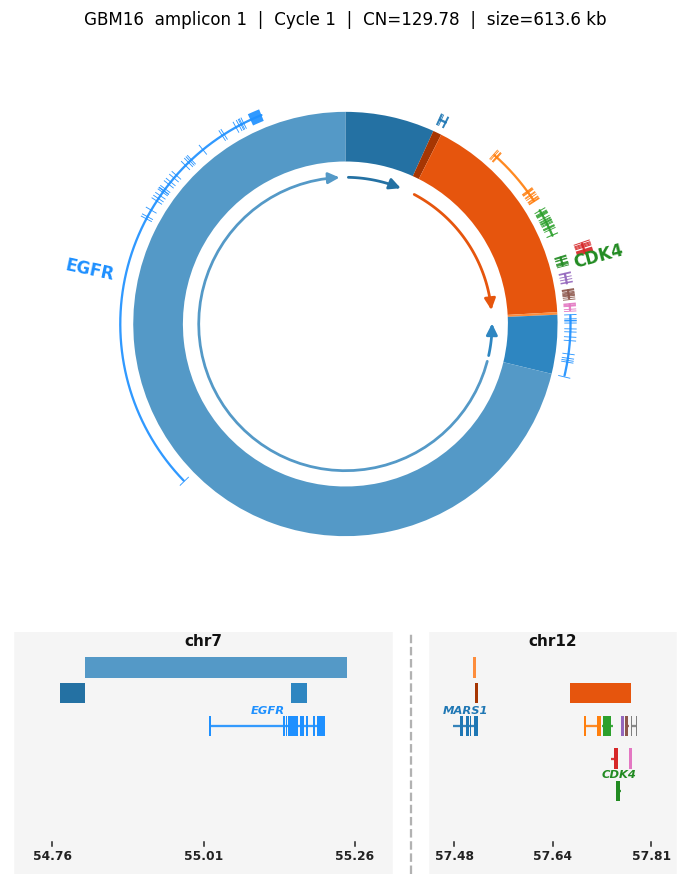

In [54]:
GENE_LABEL_COLORS = {"EGFR": "dodgerblue", "CDK4": "forestgreen"}
FOOTPRINT = ["EGFR", "CDK4", "GLI1", "TAFA2", "USP15", "GPNMB", "IGF2BP3", "NUP42", "LANCL2",
             "CCDC126", "FAM221A", "STK31", "MALSU1", "TRA2A", "MARS1", "VOPP1", "SEPTIN14"]

GBM16_FILE = str(CYCLE_FILES["GBM16, amplicon 1"])
GBM16_CYCLE = 1          # cycle id of the combined EGFR + CDK4 cycle (see the table in 1.4)

seg_colors = build_chrom_locked_segment_colors(GBM16_FILE, cycle_id=GBM16_CYCLE, merge_gap=3000)   # chr7 cool, chr12 warm

fig = plot_cycle(
    GBM16_FILE, cycle_id=GBM16_CYCLE,
    gene_df=gene_df, exon_dict=exon_dict,
    color_map=GENE_LABEL_COLORS, segment_colors=seg_colors,
    annotate_genes=["EGFR", "CDK4", "GLI1"], footprint_genes=FOOTPRINT,
    merge_gap=3000, min_cn=5, figsize=(8, 10),
    scale_to_size=False, donut_size=0.6, donut_cx=0.5, donut_cy=0.55, footprint_height=0.22,
    show_title=True, rotate_deg=0, sample_label=f"{GBM_ID['UM220']}  amplicon 1",
)
#fig.savefig(OUT / "fig4A_GBM16_cycle.png", dpi=300, facecolor="white")
plt.close(fig)

### 1.6 Figure 4B: GBM02, *EGFR* and *CDK4* on separate ecDNAs

*EGFR* (copy number 22, 1,012 kb) and *CDK4* (copy number 10, 1,327 kb) are in two different reconstructed cycles, and no HiFi read
supports a chr7-chr12 junction.

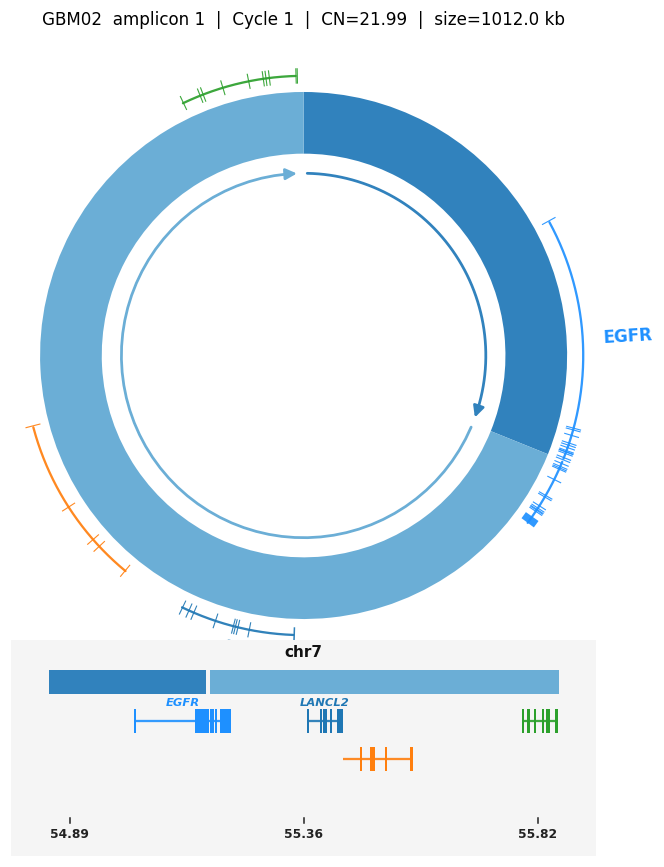

In [55]:
ANNOTATE = ["EGFR", "CDK4", "MDM2", "GLI1", "CDKN2A", "SEC61G", "LANCL2"]

fig = plot_cycle(
    str(CYCLE_FILES["GBM02, amplicon 1"]), cycle_id=1,
    gene_df=gene_df, exon_dict=exon_dict,
    color_map=GENE_LABEL_COLORS,
    min_cn=5, annotate_genes=ANNOTATE,
    figsize=(7, 7), merge_gap=3000, sample_label=f"{GBM_ID['UM116']}  amplicon 1",
)
fig.savefig(OUT / "fig4B_GBM02_EGFR_cycle.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.close(fig)

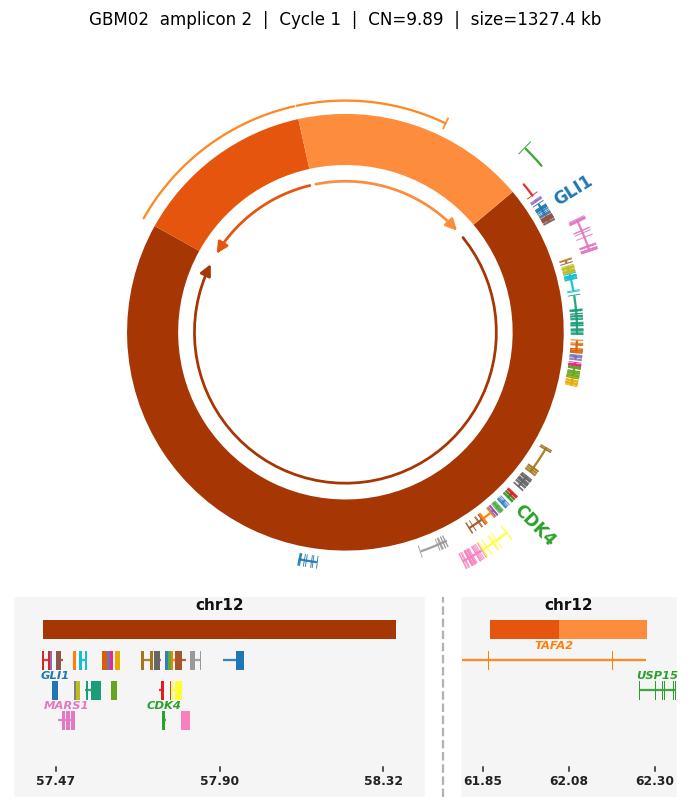

In [56]:
WARMS = ["#A63603", "#E6550D", "#FD8D3C", "#FDAE6B", "#FDD0A2", "#D94801", "#B5390A"]
ANNOTATE_CDK4 = ["EGFR", "CDK4", "GLI1", "GPNMB", "IGF2BP3"]

fig = plot_cycle(
    str(CYCLE_FILES["GBM02, amplicon 2"]), cycle_id=1,
    gene_df=gene_df, exon_dict=exon_dict,
    color_map=None, min_cn=5,
    annotate_genes=ANNOTATE_CDK4, footprint_genes=FOOTPRINT,
    figsize=(8, 6.5), merge_gap=3000, rotate_deg=50,
    show_title=True, scale_to_size=False, reference_kb=100,
    segment_colors=WARMS, sample_label=f"{GBM_ID['UM116']}  amplicon 2",
)
fig.savefig(OUT / "fig4B_GBM02_CDK4_cycle.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.close(fig)

# Part 2. EGFRvIII / EGFRvII: genomic deletions and transcript fractions (Figure 4C, D)

## 2.1 Find EGFR deletion junctions and the genomic variant allele fraction

For each tumor we take the PAF of HiFi reads that touch chr7:49-59 Mb (each read re-mapped whole, so its split alignments are
all present) and:

1. keep primary alignments with MAPQ >= 30;
2. find **deletion junctions** between consecutive alignments of the same read: same chromosome and strand, >= 500 bp of aligned
   sequence on each side, alignments that meet within the read (gap <= 500 bp, overlap <= 200 bp), and a deletion >= 1 kb. Deletions that minimap2 keeps *inside a single alignment* (a long `D` in the CIGAR, read from the
   PAF `cg` tag) are found with the same size and anchor rules and pooled with the split-read junctions. This matters for the
   7.4-kb EGFRvII deletion in GBM02: its reads have no second alignment and are continuous across the breakpoint, so without this
   step they would be counted as **wild-type**;
3. **cluster** junctions whose breakpoints differ by <= 50 bp and keep clusters supported by >= 5 unique reads;
4. keep clusters that lie inside *EGFR* and label them *EGFRvIII* when the downstream breakpoint falls on the exon-8 side of the
   exon 2-7 deletion;
5. count **wild-type molecules**: reads that continuously span each breakpoint with >= 500 bp on both sides.

The **primary gVAF** uses the upstream (left) breakpoint: mutant molecules / (mutant + wild-type molecules spanning that
breakpoint). The downstream breakpoint is reported as an independent check, as are the original-style estimate and a
Wilson 95% interval.

**Configuration and PAF reading**

In [57]:
import gzip
from pathlib import Path

import numpy as np
import pandas as pd


# =============================================================================
# Configuration
# =============================================================================

SAMPLE_ORDER = [
    "UM29", "UM29_Cells", "UM116", "UM116_Cells", "UM124", "UM130",
    "UM141", "UM146", "UM159", "UM170", "UM209", "UM215", "UM220",
    "UM233", "UM233_Cells", "UM244", "UM258",
]

# PAF files:
#   {sample}_Tumor_chr7_49_59mb.paf.gz
PAF_SUFFIX = "_Tumor_chr7_49_59mb.paf.gz"

EGFR_CHROM = "chr7"
EGFR_START = 55_019_017
EGFR_END   = 55_211_628

# EGFRvIII downstream breakpoint:
# genomic breakpoint near the exon 8 side of the exon 2-7 deletion.
VIII_3P_MIN = 55_153_953
VIII_3P_MAX = 55_155_960
VIII_3P_WIGGLE = 500

# Alignment filtering.
#
# Because these are HiFi reads, MAPQ 30 plus substantial alignment anchors is
# usually a reasonable main setting. It is still worth rerunning with 20 and 50
# as a sensitivity analysis.
MIN_MAPQ = 30

# Minimum aligned reference length on BOTH sides of a deletion junction.
MIN_JUNCTION_ANCHOR = 500

# Consecutive query alignments should meet approximately at the junction.
# Small overlaps are common with supplementary alignments and microhomology.
MAX_QUERY_GAP = 500
MAX_QUERY_OVERLAP = 200

# Cluster junction coordinates that differ slightly because of alignment
# placement, indels, clipping, or breakpoint microhomology.
BREAKPOINT_CLUSTER_TOL = 50

# Minimum number of unique HiFi molecules supporting a junction cluster.
MIN_SUPPORT = 5

# WT molecule definition:
# A WT read must span a genomic breakpoint with this much aligned sequence
# on each side.
WT_ANCHOR = 500

# Optional full-WT spanner diagnostic. For a large vIII deletion, relatively
# few HiFi molecules may span the complete retained interval.
FULL_SPAN_FLANK = 200

# Require the genomic deletion to be at least this large. This avoids treating
# tiny reference gaps as EGFR structural deletions.
MIN_DELETION_SIZE = 1_000


# =============================================================================
# PAF loading
# =============================================================================

PAF_COLS = [
    "qname", "qlen", "qstart", "qend", "strand",
    "tname", "tlen", "tstart", "tend",
    "nmatch", "alen", "mapq",
]

INT_COLS = [
    "qlen", "qstart", "qend",
    "tlen", "tstart", "tend",
    "nmatch", "alen", "mapq",
]


def parse_optional_paf_tags(parts):
    """
    Parse optional PAF tags after the first 12 mandatory fields.

    Returns a dictionary such as:
        {
            "tp": "P",
            "NM": 4,
            ...
        }

    Important minimap2 tag:
        tp:A:P = primary alignment
        tp:A:S = secondary alignment
    """
    tags = {}

    for tag_field in parts[12:]:
        fields = tag_field.split(":", 2)
        if len(fields) != 3:
            continue

        tag, tag_type, value = fields

        if tag_type in {"i", "I"}:
            try:
                value = int(value)
            except ValueError:
                pass
        elif tag_type == "f":
            try:
                value = float(value)
            except ValueError:
                pass

        tags[tag] = value

    return tags


def read_paf(path):
    """
    Read a plain-text or gzipped PAF.

    Secondary alignments are retained in the table but marked using the
    `is_secondary` column when the minimap2 tp tag is available.
    """
    rows = []
    opener = gzip.open if str(path).endswith(".gz") else open

    with opener(path, "rt") as fh:
        for line_number, line in enumerate(fh, start=1):
            line = line.rstrip("\n")

            if not line:
                continue

            parts = line.split("\t")

            if len(parts) < 12:
                print(
                    f"[WARNING] Skipping malformed PAF line "
                    f"{line_number} in {path}"
                )
                continue

            tags = parse_optional_paf_tags(parts)

            row = dict(zip(PAF_COLS, parts[:12]))
            row["tp"] = tags.get("tp", None)
            row["is_secondary"] = tags.get("tp", None) == "S"
            row["NM"] = tags.get("NM", np.nan)
            row["cg"] = tags.get("cg", None)

            rows.append(row)

    df = pd.DataFrame(rows)

    if df.empty:
        return pd.DataFrame(
            columns=PAF_COLS + ["tp", "is_secondary", "NM", "cg"]
        )

    for col in INT_COLS:
        df[col] = pd.to_numeric(df[col], errors="raise").astype(int)

    # Reference-aligned span is more transparent than the PAF block length
    # when imposing breakpoint anchors.
    df["ref_span"] = df["tend"] - df["tstart"]
    df["query_span"] = df["qend"] - df["qstart"]

    return df

**Split-read deletion junctions and breakpoint clustering**

In [58]:
# =============================================================================
# Split-read junction extraction
# =============================================================================

JUNCTION_COLS = [
    "qname",
    "chrom",
    "left_bp",
    "right_bp",
    "deletion_size",
    "strand",
    "query_gap",
    "left_anchor",
    "right_anchor",
    "mapq_left",
    "mapq_right",
]


def normalize_deletion_pair(a, b):
    """
    Convert two consecutive query-ordered alignments into normalized genomic
    deletion coordinates.

    PAF qstart/qend coordinates are always reported relative to the forward
    query sequence. Therefore, after sorting by qstart:

    Plus-strand read:
        alignment a is genomic-left
        alignment b is genomic-right

        left breakpoint  = a.tend
        right breakpoint = b.tstart

    Minus-strand read:
        alignment a is genomic-right
        alignment b is genomic-left

        left breakpoint  = b.tend
        right breakpoint = a.tstart

    Returns None if the pair does not have simple same-chromosome,
    same-orientation deletion geometry.
    """
    if a["tname"] != b["tname"]:
        return None

    if a["strand"] != b["strand"]:
        return None

    strand = a["strand"]

    if strand == "+":
        left_aln = a
        right_aln = b

        left_bp = int(a["tend"])
        right_bp = int(b["tstart"])

    elif strand == "-":
        left_aln = b
        right_aln = a

        left_bp = int(b["tend"])
        right_bp = int(a["tstart"])

    else:
        return None

    if left_bp >= right_bp:
        return None

    return {
        "chrom": a["tname"],
        "left_bp": left_bp,
        "right_bp": right_bp,
        "deletion_size": right_bp - left_bp,
        "strand": strand,
        "left_anchor": int(left_aln["ref_span"]),
        "right_anchor": int(right_aln["ref_span"]),
        "mapq_left": int(left_aln["mapq"]),
        "mapq_right": int(right_aln["mapq"]),
    }


def extract_deletion_junctions(
    paf,
    min_mapq=MIN_MAPQ,
    min_anchor=MIN_JUNCTION_ANCHOR,
    max_query_gap=MAX_QUERY_GAP,
    max_query_overlap=MAX_QUERY_OVERLAP,
    min_deletion_size=MIN_DELETION_SIZE,
):
    """
    Extract simple deletion junctions from consecutive alignments of the same
    HiFi molecule.

    Requirements:
      1. Both alignments pass MAPQ.
      2. Neither alignment is marked secondary.
      3. Same chromosome.
      4. Same strand.
      5. Adequate aligned sequence on both sides.
      6. Query alignments approximately meet.
      7. Positive genomic deletion of at least min_deletion_size.

    One read can theoretically yield more than one candidate junction if it
    contains a complex structure. Final support is counted by unique qname.
    """
    records = []

    if paf.empty:
        return pd.DataFrame(columns=JUNCTION_COLS)

    usable = paf[
        (paf["mapq"] >= min_mapq) &
        (~paf["is_secondary"])
    ].copy()

    for qname, grp in usable.groupby("qname", sort=False):
        if len(grp) < 2:
            continue

        grp = grp.sort_values(
            ["qstart", "qend", "tname", "tstart", "tend"]
        )

        alns = grp.to_dict("records")

        for i in range(len(alns) - 1):
            a = alns[i]
            b = alns[i + 1]

            query_gap = int(b["qstart"] - a["qend"])

            if query_gap > max_query_gap:
                continue

            if query_gap < -max_query_overlap:
                continue

            norm = normalize_deletion_pair(a, b)

            if norm is None:
                continue

            if norm["deletion_size"] < min_deletion_size:
                continue

            if norm["left_anchor"] < min_anchor:
                continue

            if norm["right_anchor"] < min_anchor:
                continue

            records.append({
                "qname": qname,
                **norm,
                "query_gap": query_gap,
            })

    if not records:
        return pd.DataFrame(columns=JUNCTION_COLS)

    out = pd.DataFrame(records)

    # Prevent a duplicated alignment pair from making one read appear twice
    # at exactly the same junction.
    out = out.drop_duplicates(
        subset=["qname", "chrom", "left_bp", "right_bp"]
    ).reset_index(drop=True)

    return out[JUNCTION_COLS]


# -----------------------------------------------------------------------------
# Deletions written inside ONE alignment (a long "D" in the CIGAR)
# -----------------------------------------------------------------------------
# minimap2 does not always split a read at a deletion: a deletion of a few kb can be kept as a long
# "D" operation inside a single alignment (as for the 7.4-kb EGFRvII deletion). Such a read has no
# second alignment, so the split-read search above cannot see it; worse, its alignment is continuous
# across the breakpoint, so without this step it would be counted as WILD-TYPE. The CIGAR is read from
# the PAF `cg` tag (written by `minimap2 -c`).

CIGAR_RE = re.compile(r"(\d+)([MIDNSHP=X])")


def extract_cigar_deletions(
    paf,
    min_mapq=MIN_MAPQ,
    min_anchor=MIN_JUNCTION_ANCHOR,
    min_deletion_size=MIN_DELETION_SIZE,
):
    """
    Find deletions of at least `min_deletion_size` bp that are encoded as a "D" operation inside one
    alignment, with at least `min_anchor` bp of aligned reference on each side of the deletion within
    that alignment. Returns records in the same format as extract_deletion_junctions().

    Coordinates follow the same convention as the split-read junctions: left_bp is the end of the
    upstream sequence and right_bp is the first base retained downstream of the deletion.
    """
    if paf.empty or "cg" not in paf.columns:
        return pd.DataFrame(columns=JUNCTION_COLS)

    usable = paf[
        (paf["mapq"] >= min_mapq) &
        (~paf["is_secondary"]) &
        paf["cg"].notna()
    ]

    records = []
    for aln in usable.itertuples(index=False):
        t = int(aln.tstart)                      # current reference position along the alignment
        for length, op in CIGAR_RE.findall(aln.cg):
            length = int(length)
            if op == "D" and length >= min_deletion_size:
                left_anchor = t - int(aln.tstart)
                right_anchor = int(aln.tend) - (t + length)
                if left_anchor >= min_anchor and right_anchor >= min_anchor:
                    records.append({
                        "qname": aln.qname,
                        "chrom": aln.tname,
                        "left_bp": t,
                        "right_bp": t + length,
                        "deletion_size": length,
                        "strand": aln.strand,
                        "query_gap": 0,
                        "left_anchor": left_anchor,
                        "right_anchor": right_anchor,
                        "mapq_left": int(aln.mapq),
                        "mapq_right": int(aln.mapq),
                    })
            if op in "MDN=X":                    # operations that consume reference
                t += length

    if not records:
        return pd.DataFrame(columns=JUNCTION_COLS)

    return (pd.DataFrame(records)
            .drop_duplicates(subset=["qname", "chrom", "left_bp", "right_bp"])
            .reset_index(drop=True)[JUNCTION_COLS])


# =============================================================================
# Breakpoint clustering
# =============================================================================

def cluster_breakpoints(junctions, tolerance=BREAKPOINT_CLUSTER_TOL):
    """
    Cluster nearby two-dimensional breakpoint coordinates.

    Two junction records are joined when:
        abs(left_bp_i  - left_bp_j)  <= tolerance
        abs(right_bp_i - right_bp_j) <= tolerance

    Clustering is performed separately by chromosome using connected
    components. This allows a real breakpoint to include several nearby PAF
    representations.

    The function returns the original records with an integer `cluster_id`.
    """
    if junctions.empty:
        out = junctions.copy()
        out["cluster_id"] = pd.Series(dtype=int)
        return out

    pieces = []
    next_cluster_id = 0

    for chrom, chrom_df in junctions.groupby("chrom", sort=False):
        g = chrom_df.reset_index(drop=False).copy()
        n = len(g)

        parent = list(range(n))

        def find(x):
            while parent[x] != x:
                parent[x] = parent[parent[x]]
                x = parent[x]
            return x

        def union(x, y):
            root_x = find(x)
            root_y = find(y)

            if root_x != root_y:
                parent[root_y] = root_x

        order = np.argsort(g["left_bp"].to_numpy())
        left = g["left_bp"].to_numpy()
        right = g["right_bp"].to_numpy()

        for ordered_i, i in enumerate(order):
            for j in order[ordered_i + 1:]:
                if left[j] - left[i] > tolerance:
                    break

                if abs(right[j] - right[i]) <= tolerance:
                    union(i, j)

        root_to_cluster = {}

        local_clusters = []

        for i in range(n):
            root = find(i)

            if root not in root_to_cluster:
                root_to_cluster[root] = next_cluster_id
                next_cluster_id += 1

            local_clusters.append(root_to_cluster[root])

        g["cluster_id"] = local_clusters
        pieces.append(g)

    clustered = pd.concat(pieces, ignore_index=True)

    # Restore all original junction columns plus cluster_id.
    clustered = clustered.sort_values("index").drop(columns="index")
    return clustered.reset_index(drop=True)


def summarize_clusters(clustered_junctions, min_support=MIN_SUPPORT):
    """
    Summarize each breakpoint cluster using unique HiFi molecules.

    Cluster representative coordinates are the median read-level breakpoint
    positions, rounded to the nearest integer.
    """
    if clustered_junctions.empty:
        return pd.DataFrame()

    rows = []

    for cluster_id, g in clustered_junctions.groupby("cluster_id"):
        qnames = set(g["qname"])

        n_plus = g.loc[g["strand"] == "+", "qname"].nunique()
        n_minus = g.loc[g["strand"] == "-", "qname"].nunique()
        n_cigar = g.loc[g["source"] == "cigar", "qname"].nunique() if "source" in g.columns else 0

        left_bp = int(round(g["left_bp"].median()))
        right_bp = int(round(g["right_bp"].median()))

        rows.append({
            "cluster_id": int(cluster_id),
            "chrom": g["chrom"].iloc[0],
            "left_bp": left_bp,
            "right_bp": right_bp,
            "deletion_size": right_bp - left_bp,
            "support": len(qnames),
            "support_plus": int(n_plus),
            "support_minus": int(n_minus),
            "support_cigar": int(n_cigar),
            "left_bp_min": int(g["left_bp"].min()),
            "left_bp_max": int(g["left_bp"].max()),
            "right_bp_min": int(g["right_bp"].min()),
            "right_bp_max": int(g["right_bp"].max()),
            "median_query_gap": float(g["query_gap"].median()),
            "median_left_anchor": float(g["left_anchor"].median()),
            "median_right_anchor": float(g["right_anchor"].median()),
            "mutant_qnames": qnames,
        })

    summary = pd.DataFrame(rows)

    summary = summary[
        summary["support"] >= min_support
    ].copy()

    return summary.sort_values(
        ["support", "chrom", "left_bp", "right_bp"],
        ascending=[False, True, True, True],
    ).reset_index(drop=True)

**EGFR labelling, wild-type counting and confidence intervals**

In [59]:
# =============================================================================
# EGFR event labeling
# =============================================================================

def label_egfr_cluster(row):
    """
    Label simple intragenic EGFR deletion clusters.

    EGFRvIII is identified by a downstream breakpoint in the expected
    intron-7/exon-8-side interval. The upstream breakpoint may vary.
    """
    if row["chrom"] != EGFR_CHROM:
        return None

    left_bp = int(row["left_bp"])
    right_bp = int(row["right_bp"])

    both_inside_egfr = (
        EGFR_START <= left_bp <= EGFR_END and
        EGFR_START <= right_bp <= EGFR_END
    )

    if not both_inside_egfr:
        return None

    is_viii_right_side = (
        VIII_3P_MIN - VIII_3P_WIGGLE
        <= right_bp
        <= VIII_3P_MAX + VIII_3P_WIGGLE
    )

    if is_viii_right_side:
        return "EGFRvIII"

    return "EGFR_other_deletion"


# =============================================================================
# WT molecule counting
# =============================================================================

def get_usable_chr_alignments(
    paf,
    chrom=EGFR_CHROM,
    min_mapq=MIN_MAPQ,
):
    """
    Retain high-quality, non-secondary alignments on the requested chromosome.

    We do NOT require a read to have exactly one PAF record. A molecule can have
    an unrelated supplementary alignment and still provide clear continuous WT
    support across an EGFR breakpoint.
    """
    return paf[
        (paf["tname"] == chrom) &
        (paf["mapq"] >= min_mapq) &
        (~paf["is_secondary"])
    ].copy()


def count_wt_reads(
    paf,
    left_bp,
    right_bp,
    mutant_qnames=None,
    anchor=WT_ANCHOR,
    full_span_flank=FULL_SPAN_FLANK,
    min_mapq=MIN_MAPQ,
):
    """
    Count unique WT-supporting HiFi molecules.

    Primary WT denominator: left-breakpoint WT reads
    -------------------------------------------------
    A continuous alignment must contain:

        at least `anchor` bp upstream of left_bp
        at least `anchor` bp downstream of left_bp

    The downstream sequence lies inside the region deleted in the mutant.
    Therefore, its presence proves that the molecule is WT at the left
    breakpoint.

    Right-breakpoint WT reads
    -------------------------
    The analogous count around the downstream breakpoint is reported as an
    independent validation:

        at least `anchor` bp upstream of right_bp
        at least `anchor` bp downstream of right_bp

    Full WT spanners
    ----------------
    Continuous alignments spanning the entire deletion interval plus flanks.
    This is highly stringent for large vIII deletions and is diagnostic only.

    Any molecule supporting the mutant breakpoint cluster is excluded from all
    WT sets to avoid double classification.
    """
    mutant_qnames = set() if mutant_qnames is None else set(mutant_qnames)

    chr_alns = get_usable_chr_alignments(
        paf,
        chrom=EGFR_CHROM,
        min_mapq=min_mapq,
    )

    left_wt = set(
        chr_alns.loc[
            (chr_alns["tstart"] <= left_bp - anchor) &
            (chr_alns["tend"] >= left_bp + anchor),
            "qname",
        ]
    )

    right_wt = set(
        chr_alns.loc[
            (chr_alns["tstart"] <= right_bp - anchor) &
            (chr_alns["tend"] >= right_bp + anchor),
            "qname",
        ]
    )

    full_wt = set(
        chr_alns.loc[
            (chr_alns["tstart"] <= left_bp - full_span_flank) &
            (chr_alns["tend"] >= right_bp + full_span_flank),
            "qname",
        ]
    )

    # A read classified as mutant should not also enter the WT denominator.
    left_wt -= mutant_qnames
    right_wt -= mutant_qnames
    full_wt -= mutant_qnames

    # Union is reported only as a diagnostic. It should not automatically be
    # used as the primary denominator because it gives WT molecules two
    # separate genomic opportunities to be sampled.
    either_side_wt = left_wt | right_wt

    return {
        "wt_left_qnames": left_wt,
        "wt_right_qnames": right_wt,
        "wt_full_qnames": full_wt,
        "wt_either_side_qnames": either_side_wt,
        "wt_left": len(left_wt),
        "wt_right": len(right_wt),
        "wt_full": len(full_wt),
        "wt_either_side": len(either_side_wt),
    }


# =============================================================================
# Confidence intervals
# =============================================================================

def wilson_interval(successes, total, z=1.959963984540054):
    """
    Wilson 95% confidence interval for a binomial proportion.
    """
    if total <= 0:
        return np.nan, np.nan

    p = successes / total
    denominator = 1 + (z ** 2 / total)

    center = (
        p + z ** 2 / (2 * total)
    ) / denominator

    half_width = (
        z
        * np.sqrt(
            p * (1 - p) / total
            + z ** 2 / (4 * total ** 2)
        )
        / denominator
    )

    return max(0.0, center - half_width), min(1.0, center + half_width)

**Per-sample analysis**

In [62]:
# =============================================================================
# Per-sample analysis
# =============================================================================

def analyze_sample(sample):
    paf_path = DATA_DIR / f"ecDNA/{sample}{PAF_SUFFIX}"

    print(f"\n{'=' * 80}")
    print(f"Processing {sample}")
    print(f"PAF: {paf_path}")

    if not paf_path.exists():
        print(f"  [SKIP] PAF not found")
        return []

    paf = read_paf(paf_path)

    if paf.empty:
        print("  [SKIP] PAF is empty")
        return []

    usable = paf[
        (paf["mapq"] >= MIN_MAPQ) &
        (~paf["is_secondary"])
    ]

    print(
        f"  Total PAF records:       {len(paf):,}\n"
        f"  Usable PAF records:      {len(usable):,}\n"
        f"  Usable unique HiFi reads:{usable['qname'].nunique():,}"
    )

    split_junctions = extract_deletion_junctions(
        paf,
        min_mapq=MIN_MAPQ,
        min_anchor=MIN_JUNCTION_ANCHOR,
        max_query_gap=MAX_QUERY_GAP,
        max_query_overlap=MAX_QUERY_OVERLAP,
        min_deletion_size=MIN_DELETION_SIZE,
    ).assign(source="split")

    cigar_junctions = extract_cigar_deletions(
        paf,
        min_mapq=MIN_MAPQ,
        min_anchor=MIN_JUNCTION_ANCHOR,
        min_deletion_size=MIN_DELETION_SIZE,
    ).assign(source="cigar")

    evidence = [d for d in (split_junctions, cigar_junctions) if not d.empty]
    junctions = pd.concat(evidence, ignore_index=True) if evidence else split_junctions

    print(
        f"  Raw deletion-junction records: {len(split_junctions):,} split-read + "
        f"{len(cigar_junctions):,} CIGAR-deletion"
    )

    if junctions.empty:
        print("  No qualifying deletion junctions.")
        return []

    clustered = cluster_breakpoints(
        junctions,
        tolerance=BREAKPOINT_CLUSTER_TOL,
    )

    cluster_summary = summarize_clusters(
        clustered,
        min_support=MIN_SUPPORT,
    )

    if cluster_summary.empty:
        print(
            f"  No clusters supported by at least "
            f"{MIN_SUPPORT} unique reads."
        )
        return []

    cluster_summary["label"] = cluster_summary.apply(
        label_egfr_cluster,
        axis=1,
    )

    egfr_clusters = cluster_summary[
        cluster_summary["label"].notna()
    ].copy()

    if egfr_clusters.empty:
        print("  No qualifying intra-EGFR deletion clusters.")
        return []

    sample_results = []

    for _, row in egfr_clusters.iterrows():
        left_bp = int(row["left_bp"])
        right_bp = int(row["right_bp"])
        mutant_qnames = set(row["mutant_qnames"])
        mutant_support = len(mutant_qnames)

        wt = count_wt_reads(
            paf=paf,
            left_bp=left_bp,
            right_bp=right_bp,
            mutant_qnames=mutant_qnames,
            anchor=WT_ANCHOR,
            full_span_flank=FULL_SPAN_FLANK,
            min_mapq=MIN_MAPQ,
        )

        # Primary estimate:
        # mutant junction molecules versus WT molecules spanning the LEFT
        # breakpoint, with matched local anchor requirements.
        primary_total = mutant_support + wt["wt_left"]

        primary_vaf = (
            mutant_support / primary_total
            if primary_total > 0
            else np.nan
        )

        ci_low, ci_high = wilson_interval(
            mutant_support,
            primary_total,
        )

        # Independent estimate using the downstream breakpoint.
        right_total = mutant_support + wt["wt_right"]

        right_vaf = (
            mutant_support / right_total
            if right_total > 0
            else np.nan
        )

        # Original-like estimate:
        # union of full spanners and left-breakpoint local WT reads.
        original_like_qnames = (
            wt["wt_left_qnames"] | wt["wt_full_qnames"]
        )

        original_like_total = (
            mutant_support + len(original_like_qnames)
        )

        original_like_vaf = (
            mutant_support / original_like_total
            if original_like_total > 0
            else np.nan
        )

        print(
            f"\n  [{row['label']}] "
            f"{row['chrom']}:{left_bp:,} -> "
            f"{row['chrom']}:{right_bp:,}"
        )
        print(
            f"    deletion size: "
            f"{(right_bp - left_bp) / 1000:,.1f} kb"
        )
        print(
            f"    breakpoint ranges:\n"
            f"      left:  {int(row['left_bp_min']):,}-"
            f"{int(row['left_bp_max']):,}\n"
            f"      right: {int(row['right_bp_min']):,}-"
            f"{int(row['right_bp_max']):,}"
        )
        print(
            f"    mutant support: {mutant_support} unique HiFi reads "
            f"(plus={int(row['support_plus'])}, "
            f"minus={int(row['support_minus'])}, "
            f"in-CIGAR deletions={int(row['support_cigar'])})"
        )
        print(
            f"    WT support: left={wt['wt_left']}, "
            f"right={wt['wt_right']}, "
            f"full={wt['wt_full']}"
        )
        print(
            f"    primary left-breakpoint gVAF: "
            f"{primary_vaf:.3f} "
            f"(95% CI {ci_low:.3f}-{ci_high:.3f})"
        )
        print(
            f"    right-breakpoint gVAF: "
            f"{right_vaf:.3f}"
        )

        sample_results.append({
            "sample": sample,
            "label": row["label"],
            "chrom": row["chrom"],
            "cluster_id": int(row["cluster_id"]),

            "left_bp": left_bp,
            "right_bp": right_bp,
            "left_bp_min": int(row["left_bp_min"]),
            "left_bp_max": int(row["left_bp_max"]),
            "right_bp_min": int(row["right_bp_min"]),
            "right_bp_max": int(row["right_bp_max"]),

            "deletion_size_bp": right_bp - left_bp,
            "deletion_size_kb": round(
                (right_bp - left_bp) / 1000,
                3,
            ),

            "mutant_support": mutant_support,
            "mutant_support_plus": int(row["support_plus"]),
            "mutant_support_minus": int(row["support_minus"]),
            "mutant_support_cigar": int(row["support_cigar"]),

            "median_query_gap": round(
                float(row["median_query_gap"]),
                1,
            ),
            "median_left_anchor": round(
                float(row["median_left_anchor"]),
                1,
            ),
            "median_right_anchor": round(
                float(row["median_right_anchor"]),
                1,
            ),

            "wt_left": wt["wt_left"],
            "wt_right": wt["wt_right"],
            "wt_full": wt["wt_full"],
            "wt_either_side": wt["wt_either_side"],

            "primary_total": primary_total,
            "genomic_vaf": round(primary_vaf, 4),
            "genomic_vaf_ci_low": round(ci_low, 4),
            "genomic_vaf_ci_high": round(ci_high, 4),

            "right_total": right_total,
            "right_breakpoint_vaf": round(right_vaf, 4),

            "original_like_wt": len(original_like_qnames),
            "original_like_total": original_like_total,
            "original_like_vaf": round(original_like_vaf, 4),

            "min_mapq": MIN_MAPQ,
            "junction_anchor_bp": MIN_JUNCTION_ANCHOR,
            "wt_anchor_bp": WT_ANCHOR,
            "cluster_tolerance_bp": BREAKPOINT_CLUSTER_TOL,
        })

    return sample_results

**Run all tumors.** Samples ending in `_Cells` are patient-derived cell cultures analysed alongside their tumors.

In [63]:
# =============================================================================
# Main
# =============================================================================

results = []

for sample in SAMPLE_ORDER:
    try:
        results.extend(analyze_sample(sample))
    except Exception as exc:
        print(f"\n[ERROR] {sample}: {type(exc).__name__}: {exc}")


Processing UM29
PAF: /Users/isaacxu/Downloads/ecDNA/UM29_Tumor_chr7_49_59mb.paf.gz
  Total PAF records:       265,560
  Usable PAF records:      210,740
  Usable unique HiFi reads:202,207
  Raw deletion-junction records: 1,860 split-read + 679 CIGAR-deletion

  [EGFRvIII] chr7:55,131,769 -> chr7:55,155,248
    deletion size: 23.5 kb
    breakpoint ranges:
      left:  55,131,765-55,131,769
      right: 55,155,248-55,155,253
    mutant support: 840 unique HiFi reads (plus=390, minus=450, in-CIGAR deletions=0)
    WT support: left=128, right=98, full=0
    primary left-breakpoint gVAF: 0.868 (95% CI 0.845-0.888)
    right-breakpoint gVAF: 0.896

Processing UM29_Cells
PAF: /Users/isaacxu/Downloads/ecDNA/UM29_Cells_Tumor_chr7_49_59mb.paf.gz
  Total PAF records:       90,591
  Usable PAF records:      70,686
  Usable unique HiFi reads:67,587
  Raw deletion-junction records: 782 split-read + 285 CIGAR-deletion

  [EGFRvIII] chr7:55,131,769 -> chr7:55,155,248
    deletion size: 23.5 kb
    b

In [64]:
# =============================================================================
# Output
# =============================================================================

results_df = pd.DataFrame(results)

print("\n\n" + "=" * 80)
print("EGFR DELETION SUMMARY")
print("=" * 80)

if results_df.empty: 
    print("No qualifying EGFR deletion clusters found.")
else:
    display_cols = [
        "sample",
        "label",
        "left_bp",
        "right_bp",
        "deletion_size_kb",
        "mutant_support",
        "mutant_support_plus",
        "mutant_support_minus",
        "mutant_support_cigar",
        "wt_left",
        "wt_right",
        "wt_full",
        "genomic_vaf",
        "genomic_vaf_ci_low",
        "genomic_vaf_ci_high",
        "right_breakpoint_vaf",
        "original_like_vaf",
    ]

    print(
        results_df[display_cols].to_string(
            index=False
        )
    )

out_path = OUT / "egfr_deletion_vaf_summary.tsv"

results_df.to_csv(out_path, sep="\t", index=False)

print(f"\nSaved to: {out_path}")



EGFR DELETION SUMMARY
     sample               label  left_bp  right_bp  deletion_size_kb  mutant_support  mutant_support_plus  mutant_support_minus  mutant_support_cigar  wt_left  wt_right  wt_full  genomic_vaf  genomic_vaf_ci_low  genomic_vaf_ci_high  right_breakpoint_vaf  original_like_vaf
       UM29            EGFRvIII 55131769  55155248            23.479             840                  390                   450                     0      128        98        0       0.8678              0.8450               0.8877                0.8955             0.8678
 UM29_Cells            EGFRvIII 55131769  55155248            23.479             393                  195                   198                     0       40        36        0       0.9076              0.8766               0.9314                0.9161             0.9076
      UM116 EGFR_other_deletion 55161847  55169209             7.362             671                  322                   349                   611      10

## 2.2 Label EGFRvIII and EGFRvII and choose one deletion per tumor

The labelling in 2.1 flags EGFRvIII by its downstream breakpoint. EGFRvII is the deletion of exons 14-15, i.e. an upstream
breakpoint in intron 13 and a downstream breakpoint in intron 15. For each tumor (cell cultures excluded) and variant, the
cluster with the most supporting molecules is kept. GBM06 (`UM141`) is excluded from this analysis.

In [65]:
INTRON_13 = (55_161_632, 55_163_732)     # between exon 13 and exon 14
INTRON_15 = (55_165_438, 55_171_174)     # between exon 15 and exon 16

def egfr_variant(row):
    if row["label"] == "EGFRvIII":
        return "vIII"
    if INTRON_13[0] <= row["left_bp"] <= INTRON_13[1] and INTRON_15[0] <= row["right_bp"] <= INTRON_15[1]:
        return "vII"
    return "other"

results_df["variant"] = results_df.apply(egfr_variant, axis=1)
results_df["UM"] = results_df["sample"].map(um_id)
results_df["GBM"] = results_df["UM"].map(GBM_ID)

excluded = sorted(set(results_df.loc[results_df["UM"].isin(EXCLUDE_UM), "GBM"]))
if excluded:
    print("excluded from the variant analysis:", ", ".join(excluded))
results_df = results_df[~results_df["UM"].isin(EXCLUDE_UM)]

deletions = (results_df[~results_df["sample"].str.contains("_Cells") & results_df["variant"].isin(["vIII", "vII"])]
             .sort_values("mutant_support", ascending=False)
             .drop_duplicates(["sample", "variant"])
             .sort_values(["left_bp", "right_bp"]).reset_index(drop=True))

deletions[["GBM", "variant", "left_bp", "right_bp", "deletion_size_kb", "mutant_support", "mutant_support_cigar",
           "wt_left", "genomic_vaf", "genomic_vaf_ci_low", "genomic_vaf_ci_high", "right_breakpoint_vaf"]]

excluded from the variant analysis: GBM06


,GBM,variant,left_bp,right_bp,deletion_size_kb,mutant_support,mutant_support_cigar,wt_left,genomic_vaf,genomic_vaf_ci_low,genomic_vaf_ci_high,right_breakpoint_vaf
0,GBM19,vIII,55082955,55154412,71.457,1150,0,89,0.9282,0.9124,0.9413,0.9200
1,GBM14,vIII,55125525,55155106,29.581,13,0,27,0.3250,0.2008,0.4798,0.4062
2,GBM20,vIII,55126869,55155190,28.321,555,0,335,0.6236,0.5913,0.6548,0.6671
3,GBM08,vIII,55130156,55154036,23.880,47,0,460,0.0927,0.0704,0.1211,0.0987
4,GBM01,vIII,55131769,55155248,23.479,840,0,128,0.8678,0.8450,0.8877,0.8955
5,GBM03,vIII,55134458,55155578,21.120,1753,0,1942,0.4744,0.4584,0.4905,0.4874
6,GBM02,vII,55161847,55169209,7.362,671,611,102,0.8680,0.8424,0.8901,0.8760


## 2.3 Transcript allele fraction from RNA-seq splice junctions

The splice-junction table has one row per sample and junction (STAR `SJ.out.tab` columns: `chr`, `start`, `end`, `uniq`, ...).
Junctions are identified by their genomic coordinates (within 5 bp), using the shared splice donor so that the
variant and wild-type junctions compete directly:

| Variant | Shared donor | Variant junction | Wild-type junction |
|---|---|---|---|
| EGFRvIII (exons 2-7 skipped) | E1 donor, 55,019,365 | E1->E8 (55,155,829) | E1->E2 (55,142,285) |
| EGFRvII (exons 14-15 skipped) | E13 donor, 55,161,631 | E13->E16 (55,171,174) | E13->E14 (55,163,732) |

TAF = variant junction reads / (variant + wild-type junction reads). Junctions supported by 5 or fewer uniquely mapped reads
are ignored. RNA-seq sample identifiers are translated to tumors through `rna_sample_map.csv`, which is not distributed.

In [66]:
EGFR_VARIANTS = {
    # name : (donor coordinate, variant acceptor, canonical acceptor)
    "vIII": (55_019_365, 55_155_829, 55_142_285),   # E1->E8 vs E1->E2
    "vII":  (55_161_631, 55_171_174, 55_163_732),   # E13->E16 vs E13->E14
}

def compute_egfr_variant(sjs, variant, count_col="uniq", tol=5):
    """Per-sample variant fraction from competing junctions that share a splice donor."""
    donor, var_acc, can_acc = EGFR_VARIANTS[variant]
    df = sjs[sjs["chr"] == "chr7"].copy()
    is_can = (df["start"].sub(donor).abs() <= tol) & (df["end"].sub(can_acc).abs() <= tol)
    is_var = (df["start"].sub(donor).abs() <= tol) & (df["end"].sub(var_acc).abs() <= tol)
    rows = []
    for sample, g in df.groupby("sample"):
        can = g.loc[is_can.loc[g.index], count_col].sum()
        var = g.loc[is_var.loc[g.index], count_col].sum()
        tot = can + var
        rows.append({"sample": sample, f"{variant}_canonical": int(can), f"{variant}_variant": int(var),
                     f"{variant}_vaf": round(var / tot, 4) if tot > 0 else np.nan})
    return pd.DataFrame(rows).set_index("sample")

sjs = pd.read_csv(SJ_TABLE, sep="\t")
sjs = sjs[sjs["uniq"] > 5]

rna_map = pd.read_csv(RNA_MAP)                       # rna_id -> UM identifier
rna_to_um = {r.rna_id: um_id(r["sample"]) for _, r in rna_map.iterrows()}
sjs["sample"] = sjs["sample"].map(rna_to_um)         # tumors without a map entry become NaN and are dropped
sjs = sjs.dropna(subset=["sample"])

taf = {v: compute_egfr_variant(sjs, v) for v in EGFR_VARIANTS}
print(f"splice-junction rows kept: {len(sjs):,} across {sjs['sample'].nunique()} tumors")

splice-junction rows kept: 748 across 21 tumors


## 2.4 Combine DNA and RNA fractions

In [67]:
rows = []
for _, r in deletions.iterrows():
    t = taf[r["variant"]]
    um = r["UM"]
    rows.append({
        "GBM": r["GBM"], "variant": r["variant"],
        "bp_left": int(r["left_bp"]), "bp_right": int(r["right_bp"]), "del_kb": round(r["deletion_size_kb"], 1),
        "genomic_vaf": r["genomic_vaf"],
        "rna_taf": t.loc[um, f"{r['variant']}_vaf"] if um in t.index else np.nan,
        "rna_variant_reads": int(t.loc[um, f"{r['variant']}_variant"]) if um in t.index else 0,
        "rna_wt_reads": int(t.loc[um, f"{r['variant']}_canonical"]) if um in t.index else 0,
    })
fig4cd = pd.DataFrame(rows)
fig4cd.to_csv(OUT / "fig4CD_data.csv", index=False)
fig4cd

,GBM,variant,bp_left,bp_right,del_kb,genomic_vaf,rna_taf,rna_variant_reads,rna_wt_reads
0,GBM19,vIII,55082955,55154412,71.5,0.9282,0.9767,2393,57
1,GBM14,vIII,55125525,55155106,29.6,0.3250,0.8699,1838,275
2,GBM20,vIII,55126869,55155190,28.3,0.6236,0.8479,340,61
3,GBM08,vIII,55130156,55154036,23.9,0.0927,0.1055,108,916
4,GBM01,vIII,55131769,55155248,23.5,0.8678,0.9185,676,60
5,GBM03,vIII,55134458,55155578,21.1,0.4744,0.8041,2537,618
6,GBM02,vII,55161847,55169209,7.4,0.8680,0.8964,1843,213


**Values quoted in the Results text.** Genomic and transcript allele fractions (%) as reported in the manuscript, compared with
the values just computed (differences above 0.15 percentage points are listed).

In [68]:
QUOTED = {  # GBM: (genomic VAF %, RNA TAF %)
    "GBM08": (9.3, 10.6), "GBM19": (92.8, 97.7), "GBM01": (86.8, 91.9), "GBM02": (86.1, 89.6),
    "GBM14": (32.5, 87.0), "GBM20": (62.4, 84.8), "GBM03": (47.4, 80.4),
}
chk = fig4cd.set_index("GBM")
diffs = []
for g, (v, t) in QUOTED.items():
    if g in chk.index:
        dv, dt = 100 * chk.loc[g, "genomic_vaf"] - v, 100 * chk.loc[g, "rna_taf"] - t
        if abs(dv) > 0.15 or abs(dt) > 0.15:
            diffs.append((g, round(100 * chk.loc[g, "genomic_vaf"], 1), v, round(100 * chk.loc[g, "rna_taf"], 1), t))
print("all quoted values reproduced" if not diffs else "computed vs quoted (gVAF, TAF):")
for d in diffs:
    print(f"  {d[0]}: gVAF {d[1]} vs {d[2]}   TAF {d[3]} vs {d[4]}")

computed vs quoted (gVAF, TAF):
  GBM02: gVAF 86.8 vs 86.1   TAF 89.6 vs 89.6


## 2.5 Figure 4C, D

**C** (left): the genomic span of each deletion against the *EGFR* gene model; exons 2-7 (EGFRvIII) and 14-15 (EGFRvII) are shaded.
**D** (right): for each tumor, the genomic VAF (open circle) and the RNA TAF (filled circle, coloured by variant).

/var/folders/qz/5wwndvpx4_v74xllvh_p8vmm0000gn/T/ipykernel_49725/4273802016.py:178: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


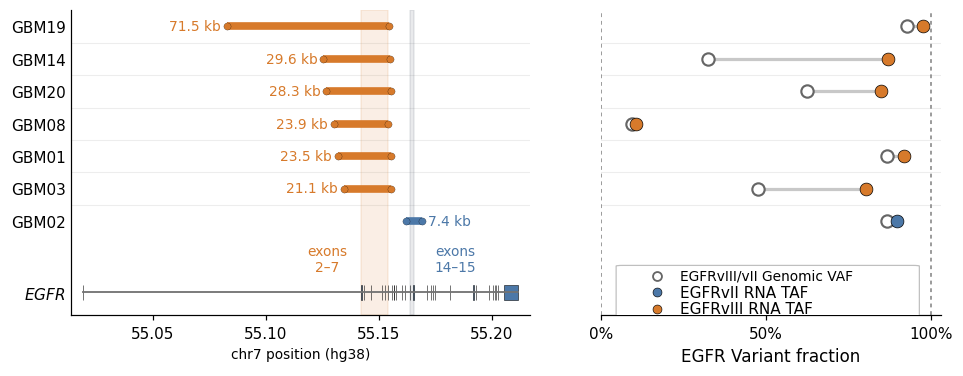

In [69]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import Rectangle, FancyBboxPatch
from matplotlib.lines import Line2D

PALETTE={
    "vIII":"#D77A2B","vII":"#4C78A8","exon":"#4C78A8","gene_line":"0.45",
    "exons_2_7":"#D77A2B","exons_14_15":"#4A5568",
    "genomic":"#666666","connector":"0.75","text":"0.15"
}
ALPHA={"span":.12,"connector":.85}
FONT={"label":11,"tick":10,"sample":10,"annot":9}
SAVE=True
OUTPREFIX=str(OUT / "fig4CD_egfr_vaf_taf")

DATA = [(r.GBM, r.variant, r.bp_left, r.bp_right, r.del_kb, r.genomic_vaf, r.rna_taf)
        for r in fig4cd.itertuples()]

EGFR_FEATURES_RAW=[
    ("exon","ENSE00001841347","55,019,017","55,019,365"),
    ("intron","Intron 1-2","55,019,366","55,142,285"),
    ("exon","ENSE00003541288","55,142,286","55,142,437"),
    ("intron","Intron 2-3","55,142,438","55,143,304"),
    ("exon","ENSE00001704157","55,143,305","55,143,488"),
    ("intron","Intron 3-4","55,143,489","55,146,605"),
    ("exon","ENSE00001798125","55,146,606","55,146,740"),
    ("intron","Intron 4-5","55,146,741","55,151,293"),
    ("exon","ENSE00001683983","55,151,294","55,151,362"),
    ("intron","Intron 5-6","55,151,363","55,152,545"),
    ("exon","ENSE00001652975","55,152,546","55,152,664"),
    ("intron","Intron 6-7","55,152,665","55,154,010"),
    ("exon","ENSE00001623732","55,154,011","55,154,152"),
    ("intron","Intron 7-8","55,154,153","55,155,829"),
    ("exon","ENSE00001751179","55,155,830","55,155,946"),
    ("intron","Intron 8-9","55,155,947","55,156,532"),
    ("exon","ENSE00001084929","55,156,533","55,156,659"),
    ("intron","Intron 9-10","55,156,660","55,156,758"),
    ("exon","ENSE00001084931","55,156,759","55,156,832"),
    ("intron","Intron 10-11","55,156,833","55,157,662"),
    ("exon","ENSE00001084926","55,157,663","55,157,753"),
    ("intron","Intron 11-12","55,157,754","55,160,138"),
    ("exon","ENSE00001084941","55,160,139","55,160,338"),
    ("intron","Intron 12-13","55,160,339","55,161,498"),
    ("exon","ENSE00001084939","55,161,499","55,161,631"),
    ("intron","Intron 13-14","55,161,632","55,163,732"),
    ("exon","ENSE00001084927","55,163,733","55,163,823"),
    ("intron","Intron 14-15","55,163,824","55,165,279"),
    ("exon","ENSE00001627115","55,165,280","55,165,437"),
    ("intron","Intron 15-16","55,165,438","55,171,174"),
    ("exon","ENSE00001768076","55,171,175","55,171,213"),
    ("intron","Intron 16-17","55,171,214","55,172,982"),
    ("exon","ENSE00002684637","55,172,983","55,173,124"),
    ("intron","Intron 17-18","55,173,125","55,173,920"),
    ("exon","ENSE00001778519","55,173,921","55,174,043"),
    ("intron","Intron 18-19","55,174,044","55,174,721"),
    ("exon","ENSE00001756460","55,174,722","55,174,820"),
    ("intron","Intron 19-20","55,174,821","55,181,292"),
    ("exon","ENSE00001601336","55,181,293","55,181,478"),
    ("intron","Intron 20-21","55,181,479","55,191,718"),
    ("exon","ENSE00001681524","55,191,719","55,191,874"),
    ("intron","Intron 21-22","55,191,875","55,192,765"),
    ("exon","ENSE00001631695","55,192,766","55,192,841"),
    ("intron","Intron 22-23","55,192,842","55,198,716"),
    ("exon","ENSE00003625684","55,198,717","55,198,863"),
    ("intron","Intron 23-24","55,198,864","55,200,315"),
    ("exon","ENSE00001790701","55,200,316","55,200,413"),
    ("intron","Intron 24-25","55,200,414","55,201,187"),
    ("exon","ENSE00001801208","55,201,188","55,201,355"),
    ("intron","Intron 25-26","55,201,356","55,201,734"),
    ("exon","ENSE00001773562","55,201,735","55,201,782"),
    ("intron","Intron 26-27","55,201,783","55,202,516"),
    ("exon","ENSE00001795780","55,202,517","55,202,625"),
    ("intron","Intron 27-28","55,202,626","55,205,255"),
    ("exon","ENSE00001245887","55,205,256","55,211,628"),
]

def clean_pos(x): return int(str(x).replace(",",""))

egfr=pd.DataFrame(EGFR_FEATURES_RAW,columns=["type","name","start","end"])
egfr[["start","end"]]=egfr[["start","end"]].map(clean_pos)
exons=egfr[egfr.type=="exon"].copy()
exons["exon_num"]=np.arange(1,len(exons)+1)

df=pd.DataFrame(DATA,columns=["sample","variant","posA","posB","size_kb","genomic_vaf","rna_taf"])
df=df.sort_values(["posA","posB"]).reset_index(drop=True)

y=np.arange(len(df)); y_gene=len(df)+1.2
xmin=min(df.posA.min(),egfr.start.min())-5000
xmax=max(df.posB.max(),egfr.end.max())+5000

e2=exons.loc[exons.exon_num==2,"start"].iloc[0]
e7=exons.loc[exons.exon_num==7,"end"].iloc[0]
e14=exons.loc[exons.exon_num==14,"start"].iloc[0]
e15=exons.loc[exons.exon_num==15,"end"].iloc[0]

fig=plt.figure(figsize=(10.2,3.6))
gs=fig.add_gridspec(1,2,width_ratios=[1.35,1],wspace=.18)
ax_del=fig.add_subplot(gs[0,0])
ax_dumb=fig.add_subplot(gs[0,1],sharey=ax_del)

# ---------------- row separators ----------------
for i in range(len(df)-1):
    yy=i+.5
    ax_del.axhline(yy,color="0.93",lw=.7,zorder=0)
    ax_dumb.axhline(yy,color="0.93",lw=.7,zorder=0)

# ---------------- left: deletions ----------------
ax_del.axvspan(e2,e7,color=PALETTE["exons_2_7"],alpha=ALPHA["span"],zorder=0)
ax_del.axvspan(e14,e15,color=PALETTE["exons_14_15"],alpha=ALPHA["span"],zorder=0)

for i,r in df.iterrows():
    c=PALETTE[r.variant]
    ax_del.plot([r.posA,r.posB],[i,i],color=c,lw=5,solid_capstyle="butt",zorder=3)
    ax_del.scatter([r.posA,r.posB],[i,i],color=c,edgecolor="black",linewidth=.15,s=22,zorder=4)
    x=r.posA-2700 if r.variant=="vIII" else r.posB+2700
    ha="right" if r.variant=="vIII" else "left"
    ax_del.text(x,i,f"{r.size_kb:.1f} kb",ha=ha,va="center",fontsize=FONT["annot"],color=c)

ax_del.plot([egfr.start.min(),egfr.end.max()],[y_gene,y_gene],color=PALETTE["gene_line"],lw=1.2)
for _,r in exons.iterrows():
    ax_del.add_patch(Rectangle((r.start,y_gene-.22),r.end-r.start,.44,
                               fc=PALETTE["exon"],ec="black",lw=.35))

ax_del.text(e2-15000,y_gene-1.5,"exons\n2–7",ha="center",va="top",
            fontsize=FONT["annot"],color=PALETTE["vIII"])
ax_del.text(e15+18500,y_gene-1.5,"exons\n14–15",ha="center",va="top",
            fontsize=FONT["annot"],color=PALETTE["vII"])

ax_del.set(xlim=(xmin,xmax),ylim=(y_gene+.7,-.5),xlabel="chr7 position (hg38)")
ax_del.set_yticks(list(y)+[y_gene])
ax_del.set_yticklabels(list(df["sample"])+[r"$\it{EGFR}$"], fontsize=FONT["sample"])
ax_del.set_xticks([55.05e6,55.10e6,55.15e6,55.20e6])
ax_del.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_:f"{x/1e6:.2f}"))
ax_del.tick_params(axis="y",length=0)
ax_del.tick_params(axis="x",labelsize=FONT["tick"])
ax_del.spines[["top","right"]].set_visible(False)

# ---------------- right: VAF / TAF ----------------
for i,r in df.iterrows():
    c=PALETTE[r.variant]
    ax_dumb.plot([r.genomic_vaf,r.rna_taf],[i,i],color=PALETTE["connector"],
                 lw=2.1,alpha=ALPHA["connector"],zorder=1)
    ax_dumb.scatter(r.genomic_vaf,i,s=65,fc="white",ec=PALETTE["genomic"],lw=1.4,zorder=3)
    ax_dumb.scatter(r.rna_taf,i,s=70,fc=c,ec="black",lw=.45,zorder=4)

ax_dumb.set_xlim(0,1.03)
ax_dumb.set_xticks([0,.5,1])
ax_dumb.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax_dumb.set_xlabel("EGFR Variant fraction",fontsize=FONT["label"])
ax_dumb.tick_params(axis="y",left=False,labelleft=False)
ax_dumb.tick_params(axis="x",labelsize=FONT["tick"])
ax_dumb.spines[["top","right","left"]].set_visible(False)

ax_dumb.axvline(0,color="#808080",lw=1,ls=(0,(2.5,2.5)),zorder=0)
ax_dumb.axvline(1,color="#808080",lw=1,ls=(0,(2.5,2.5)),zorder=0)

# ---------------- manual legend ----------------
legend_y=y_gene
box_x,box_y,box_w,box_h=.08,legend_y-.80,.85,1.65
ax_dumb.add_patch(FancyBboxPatch(
    (box_x,box_y),box_w,box_h,
    boxstyle="round,pad=0.035,rounding_size=0.02",
    transform=ax_dumb.transData,fc="white",ec=".75",lw=.8,zorder=5
))

mx,tx=.17,.24
yg,y2,y3=legend_y-.50,legend_y,legend_y+.50

ax_dumb.scatter(mx,yg,s=34,fc="white",ec=PALETTE["genomic"],lw=1.2,zorder=6)
ax_dumb.text(tx,yg,"EGFRvIII/vII Genomic VAF",va="center",fontsize=FONT["tick"]-1,zorder=6)

ax_dumb.scatter(mx,y2,s=34,fc=PALETTE["vII"],ec="black",lw=.4,zorder=6)
ax_dumb.text(tx,y2,"EGFRvII RNA TAF",va="center",fontsize=FONT["tick"],zorder=6)

ax_dumb.scatter(mx,y3,s=34,fc=PALETTE["vIII"],ec="black",lw=.4,zorder=6)
ax_dumb.text(tx,y3,"EGFRvIII RNA TAF",va="center",fontsize=FONT["tick"],zorder=6)

plt.tight_layout()

if SAVE:
    plt.savefig(f"{OUTPREFIX}_combined_deletion_vaf_taf.png",dpi=300,bbox_inches="tight")
    plt.savefig(f"{OUTPREFIX}_combined_deletion_vaf_taf.pdf",bbox_inches="tight")

plt.show()

# Part 3. GBM19: non-uniform amplification and focal superamplification (Figure 4E, F)

GBM19's EGFR amplicon is confirmed as ecDNA by FISH and is linked to its chromosome 7 locus of origin through the excision scar
(Figure 2). Coverage across the amplicon is far from flat: ten narrow intervals (labelled A-J in coordinate order) reach copy numbers
several-fold above the surrounding amplified region. The same pattern is seen in patient-derived cells (PDC).

## 3.1 Intervals and settings

The ten superamplified intervals are listed as fixed coordinates. Coverage is normalised by each sample's median genome-wide coverage
(`TUMOR_COV`, `PDC_COV`, from the mosdepth summary of each sample).

In [70]:
from matplotlib.patches import Rectangle

# ---------------- settings ----------------
SAMPLE = "UM233"
Q = "m84077_250927_022849_s4/90311119/ccs"      # the HiFi molecule shown in panel F
TUMOR_BAM = DATA_DIR / "UM233_Tumor.bam"      # only needed if read90311119.sam is not available

XLIM = (54_700_000, 55_350_000)
EGFR = (55_019_017, 55_211_628)

TUMOR_COV, PDC_COV = 76, 37
FIGSIZE_DEPTH = (7, 5)
FIGSIZE_READ  = (7, 7)

ELEMENTS = {
    "A": (54_917_655, 54_917_863),
    "B": (55_017_254, 55_017_566),
    "C": (55_039_657, 55_039_809),
    "D": (55_112_598, 55_112_932),
    "E": (55_114_499, 55_114_802),
    "F": (55_150_796, 55_151_184),
    "G": (55_187_677, 55_187_958),
    "H": (55_239_300, 55_239_612),
    "I": (55_259_003, 55_259_139),
    "J": (55_276_607, 55_276_916),
}

C_MAP = {
    "A": "#D77A2B",
    "B": "#4C78A8",
    "C": "#7F7F7F",
    "D": "#4C78A8",
    "E": "#56B4E9",
    "F": "#009E73",
    "G": "#CC79A7",
    "H": "#8C564B",
    "I": "#E41A1C",
    "J": "#9467BD",
}

C_TUMOR, C_PDC = "dodgerblue", "orangered"
C_EGFR, C_LONG, C_SHORT, C_CONN = "#8E44AD", "0.80", "0.90", "0.75"

SAVE = True
OUT1 = str(OUT / "fig4E_GBM19_depth")
OUT2 = str(OUT / "fig4F_GBM19_read_path")

# Slight x-offsets for crowded top labels
DEPTH_LABEL_DX = {
    "E": 4000,   # nudge E a little to the right
}

Lengths of the ten intervals (the Results text reports 136-388 bp, median 306 bp):

In [71]:
el = pd.DataFrame([(k, s, e, e - s) for k, (s, e) in ELEMENTS.items()], columns=["interval", "start", "end", "length_bp"])
print(f"length range {el.length_bp.min()}-{el.length_bp.max()} bp, median {el.length_bp.median():.0f} bp")
el

length range 136-388 bp, median 306 bp


,interval,start,end,length_bp
0,A,54917655,54917863,208
1,B,55017254,55017566,312
2,C,55039657,55039809,152
3,D,55112598,55112932,334
4,E,55114499,55114802,303
5,F,55150796,55151184,388
6,G,55187677,55187958,281
7,H,55239300,55239612,312
8,I,55259003,55259139,136
9,J,55276607,55276916,309


## 3.2 Figure 4E: coverage across the amplicon

Normalised 100-bp coverage of the tumor (blue) and patient-derived cells (orange). The shaded band is the *EGFR* gene. Letters mark the
ten superamplified intervals.

In [74]:
# ---------------- depth helpers ----------------
def load_depth(p):
    x = pd.read_csv(p, sep="\t", header=None, comment="#").iloc[:, :4]
    x.columns = ["chrom", "start", "end", "raw_depth"]
    x = x[x["chrom"].astype(str).isin(["chr7", "7"])].copy()          # chr7 only
    x["start"] = pd.to_numeric(x["start"], errors="coerce")           # tolerate a header row
    x["end"] = pd.to_numeric(x["end"], errors="coerce")
    x["raw_depth"] = pd.to_numeric(x["raw_depth"], errors="coerce")
    x = x.dropna(subset=["start", "end", "raw_depth"])
    x["pos"] = (x.start + x.end) / 2
    return x

def find_depth(labels, exclude=()):
    """First 100-bp depth file for SAMPLE matching one of the labels; searches DATA_DIR and its sub-folders."""
    for lab in labels:
        for pat in [f"{SAMPLE}_{lab}_chr7_49_59mb_100bp.bed.gz",            # UM233_Tumor_chr7_49_59mb_100bp.bed.gz
                    f"{SAMPLE}_{lab}_Tumor_chr7_49_59mb_100bp.bed.gz",      # UM233_Cells_Tumor_chr7_49_59mb_100bp.bed.gz
                    f"{SAMPLE}_{lab}*100bp*.bed.gz",
                    f"{SAMPLE}*{lab}*100bp*.bed.gz"]:
            hits = sorted(DATA_DIR.glob(pat)) or sorted(DATA_DIR.rglob(pat))
            hits = [h for h in hits if not any(e in h.name for e in exclude)]
            if hits:
                return hits[0]
    return None

def prep(p, cov):
    x = load_depth(p)
    x = x[x.pos.between(*XLIM)].copy()
    x["depth_norm"] = x.raw_depth / cov
    return x

tumor_file = find_depth(["Tumor"], exclude=("Cells", "PDC", "Xeno", "PDX"))
pdc_file = find_depth(["Cells", "PDC", "Xeno", "PDX"])
print("tumor depth file:", tumor_file)
print("PDC depth file:  ", pdc_file)

if tumor_file is None:
    found = sorted(p.name for p in DATA_DIR.rglob("*100bp*"))
    raise FileNotFoundError(f"No 100-bp tumor depth file for {SAMPLE} in {DATA_DIR} (or its sub-folders). "
                            f"Files containing '100bp' there: {found[:20] if found else 'none'}")

tumor = prep(tumor_file, TUMOR_COV)
pdc = prep(pdc_file, PDC_COV) if pdc_file else None

for name, d in (("tumor", tumor), ("PDC", pdc)):
    if d is not None:
        if d.empty:
            raise ValueError(f"{name}: no 100-bp bins between {XLIM[0]:,} and {XLIM[1]:,} on chr7 - is this the right file/chromosome naming?")
        print(f"{name}: {len(d):,} bins in the plotted window, peak {d.depth_norm.max():.1f}x normalised coverage")

tumor depth file: /Users/isaacxu/Downloads/ecDNA/UM233_Tumor_chr7_49_59mb_100bp.bed.gz
PDC depth file:   /Users/isaacxu/Downloads/ecDNA/UM233_Cells_Tumor_chr7_49_59mb_100bp.bed.gz
tumor: 6,500 bins in the plotted window, peak 159.9x normalised coverage
PDC: 6,500 bins in the plotted window, peak 209.2x normalised coverage


How much higher is each interval than the rest of the amplicon? Peak normalised coverage in each interval, divided by the median
coverage across the plotted region excluding the intervals (+/- 1 kb):

In [75]:
def fold_table(cov_df):
    mask = np.zeros(len(cov_df), dtype=bool)
    for s, e in ELEMENTS.values():
        mask |= cov_df.pos.between(s - 1000, e + 1000).to_numpy()
    background = cov_df.loc[~mask & cov_df.pos.between(*EGFR), "depth_norm"].median()
    peaks = {k: cov_df[(cov_df.start < e) & (cov_df.end > s)]["depth_norm"].max() for k, (s, e) in ELEMENTS.items()}
    return background, pd.Series(peaks)

bg_t, peak_t = fold_table(tumor)
summary = pd.DataFrame({"tumor_peak": peak_t.round(1), "tumor_fold": (peak_t / bg_t).round(1)})
if pdc is not None:
    bg_p, peak_p = fold_table(pdc)
    summary["pdc_peak"] = peak_p.round(1)
    summary["pdc_fold"] = (peak_p / bg_p).round(1)
print(f"background (median coverage across the EGFR gene, outside the intervals): tumor {bg_t:.1f}x" + (f", PDC {bg_p:.1f}x" if pdc is not None else ""))
summary

background (median coverage across the EGFR gene, outside the intervals): tumor 17.7x, PDC 21.1x


,tumor_peak,tumor_fold,pdc_peak,pdc_fold
A,40.2,2.3,50.4,2.4
B,159.9,9.0,209.2,9.9
C,33.3,1.9,41.4,2.0
D,122.9,7.0,159.9,7.6
E,39.6,2.2,52.1,2.5
F,39.1,2.2,51.9,2.5
G,55.9,3.2,63.6,3.0
H,96.7,5.5,121.0,5.7
I,76.1,4.3,102.1,4.8
J,105.8,6.0,129.8,6.2


## 3.3 One HiFi molecule through the superamplified intervals

To see whether the peaks reflect repeated incorporation of the same elements within single ecDNA molecules, we take one 44.3-kb HiFi
read that passes through many of them and list **all of its alignments** from the BAM (primary and supplementary): for each, the
position on the read (from the clipping in the CIGAR), the strand and the position on chr7. Each alignment is assigned to interval A-J if
at least 60% of it lies inside that interval; otherwise it is "long" (>= 500 bp of read) or "short".

In [82]:
# Alignments of the HiFi read m84077_250927_022849_s4/90311119/ccs on chr7 (SAM fields FLAG, POS [1-based], CIGAR),
# one tuple per alignment. FLAG only matters here for the strand bit (16 = reverse).
BAM_ROWS = [
    (2064, 55228233, "37086H942M1D13M1D88M1I227M1I78M1I347M1D304M1D555M1D10M1D219M1D430M1D651M1D12M1D37M1I123M1I985M1D805M1D231M1D1124M"),
    (2064, 55239310, "36784H136M1I74M1D92M7185H"),
    (2048, 55017282, "7487H176M1D108M36501H"),
    (2048, 55112607, "7770H295M36207H"),
    (2064, 55017255, "35925H215M1D71M8061H"),
    (2064, 55259019, "35806H121M8345H"),
    (2048, 55112599, "8466H314M35492H"),
    (2048, 55017343, "8774H8M1D215M35275H"),
    (2048, 55112607, "8996H292M34984H"),
    (2048, 55017290, "9288H122M1D26M1D127M34709H"),
    (2048, 55112607, "9562H295M34415H"),
    (2064, 55017255, "34131H91M1I196M9853H"),
    (2064, 55259004, "33998H5M1D36M1I59M1D34M10139H"),
    (2064, 55112607, "33717H149M1D88M1I46M10271H"),
    (2064, 55017452, "33603H115M10554H"),
    (2064, 55114500, "33312H34M1D259M10667H"),
    (2064, 55150815, "32941H370M10961H"),
    (2064, 55112607, "32621H122M1D115M1D83M11331H"),
    (2064, 55017255, "32311H203M1D108M11650H"),
    (2064, 55259037, "32210H103M11959H"),
    (2064, 55017353, "32043H108M1D63M12058H"),
    (2064, 55039658, "31891H152M12229H"),
    (2048, 55017255, "12423H206M1D105M31538H"),
    (2048, 55112607, "12733H289M1D36M31214H"),
    (2048, 55150797, "13056H388M30828H"),
    (2048, 55114500, "13445H129M1D134M30564H"),
    (2048, 55150829, "13707H289M1I67M30208H"),
    (2048, 55114500, "14065H303M29904H"),
    (16, 55237888, "8687S84M1I1474M1I282M1D303M1I992M1D923M1D361M1I517M1I1771M1D1225M1D754M1D14M1D2633M1I168M1D681M1D388M1I854M1D1045M1D65M1D740M1I3455M1D52M1D743M1I376M1I395M1D139M1D630M23D144M14367S"),
    (2064, 55239301, "8580H109M35583H"),
    (2064, 54917656, "8376H80M1I124M2D2M35689H"),
    (2048, 55187690, "35895H74M1D194M8109H"),
    (2048, 55187678, "36161H206M1D67M1D2M7836H"),
    (2048, 55276608, "36433H309M7530H"),
    (2064, 55276608, "7224H159M1D147M36742H"),
    (2064, 55187678, "6951H274M1D2M37045H"),
    (2064, 55187690, "6684H269M37319H"),
    (2048, 54917656, "37587H172M1D31M2D2M6480H"),
    (2048, 55239301, "37789H109M6374H"),
    (2048, 55237888, "37896H485M1D98M1D68M1D104M1I406M1D41M1D351M1I1322M1D1179M1D1416M1D901M3H"),
]

QLEN = 44272          # read length (bp)
print(f"read {Q}: {len(BAM_ROWS)} alignments on chr7, read length {QLEN:,} bp")

read m84077_250927_022849_s4/90311119/ccs: 40 alignments on chr7, read length 44,272 bp


In [83]:
# ---------------- BAM -> coords ----------------
def cig_ops(c):
    return [(int(n), op) for n, op in re.findall(r"(\d+)([MIDNSHP=X])", c)]

def parse_row(flag, pos, cigar):
    ops = cig_ops(cigar)
    left  = ops[0][0]  if ops[0][1]  in "HS" else 0
    right = ops[-1][0] if ops[-1][1] in "HS" else 0
    rev = bool(flag & 16)

    # query coords on original CCS read
    qstart, qend = (right, QLEN - left) if rev else (left, QLEN - right)

    # reference coords
    tstart = pos - 1
    tend = tstart + sum(n for n, op in ops if op in "MDN=X")
    return qstart, qend, "-" if rev else "+", tstart, tend

d = pd.DataFrame(BAM_ROWS, columns=["flag", "pos", "cigar"])
d[["qstart", "qend", "strand", "tstart", "tend"]] = d.apply(
    lambda r: pd.Series(parse_row(r.flag, r.pos, r.cigar)), axis=1
)
d["alen"] = d.qend - d.qstart
d["tmid"] = (d.tstart + d.tend) / 2

# ---------------- classify alignments ----------------
def ov(a, b, x):
    return max(0, min(b, x[1]) - max(a, x[0]))

def cls(r):
    L = r.tend - r.tstart
    hits = []
    for lab, iv in ELEMENTS.items():
        x = ov(r.tstart, r.tend, iv)
        if x > 0:
            hits.append((x / L, x, lab))
    if hits:
        frac, bp, lab = max(hits)
        if frac >= 0.60:
            return lab
    return "long" if r.alen >= 500 else "short"

d["type"] = d.apply(cls, axis=1)
d = d.sort_values(["qstart", "qend"]).reset_index(drop=True)
d["seg"] = np.arange(1, len(d) + 1)

print(d[["seg","qstart","qend","strand","tstart","tend","alen","cigar","type"]].to_string(index=False))
print("\nCounts:")
print(d["type"].value_counts().sort_index())

 seg  qstart  qend strand   tstart     tend  alen                                                                                                                                                                                cigar type
   1       0  7186      - 55228232 55235426  7186                                                                    37086H942M1D13M1D88M1I227M1I78M1I347M1D304M1D555M1D10M1D219M1D430M1D651M1D12M1D37M1I123M1I985M1D805M1D231M1D1124M long
   2    7185  7488      - 55239309 55239612   303                                                                                                                                                            36784H136M1I74M1D92M7185H    H
   3    7487  7771      + 55017281 55017566   284                                                                                                                                                                7487H176M1D108M36501H    B
   4    7770  8065      + 55112606 55112901   295       

In [84]:
copies = d[d["type"].isin(ELEMENTS)]["type"].value_counts().sort_index()
print("copies of each interval on this molecule:", {k: int(v) for k, v in copies.items()})
print(f"{len(d)} alignments in total; interval B x{copies.get('B', 0)}, interval D x{copies.get('D', 0)}")

copies of each interval on this molecule: {'A': 2, 'B': 9, 'C': 1, 'D': 7, 'E': 3, 'F': 3, 'G': 4, 'H': 3, 'I': 3, 'J': 2}
40 alignments in total; interval B x9, interval D x7


## 3.4 Figure 4F: alignment order along the molecule

Each row is one alignment, in read order from top to bottom; its horizontal position is where it maps on chr7. Coloured blocks are copies
of intervals A-J, grey blocks are other (long or short) alignments, and dashed lines trace the path of the read.

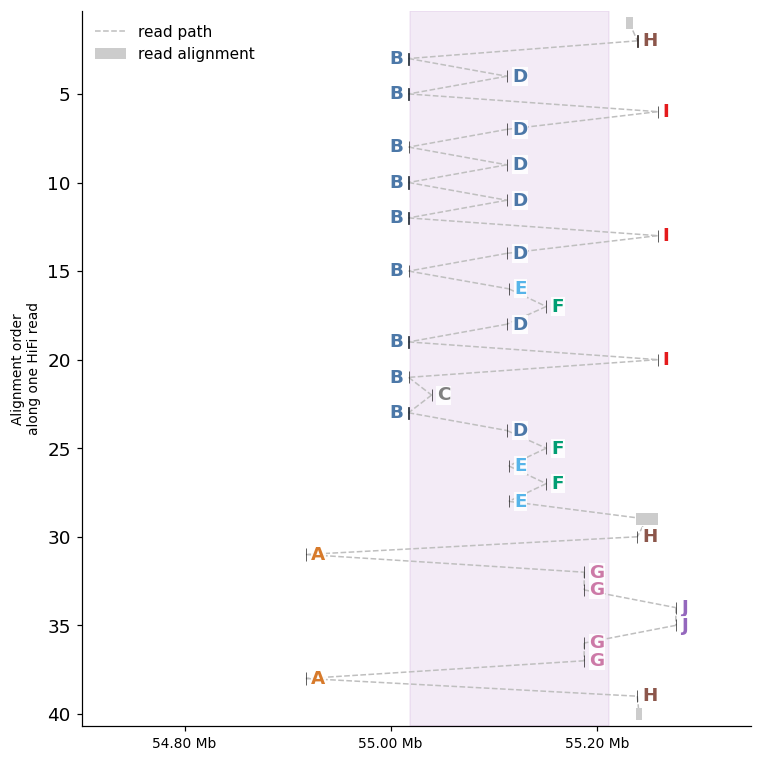

In [87]:
from matplotlib.patches import Rectangle
SAVE = False
fig, ax = plt.subplots(figsize=FIGSIZE_READ)
ax.axvspan(*EGFR, color=C_EGFR, alpha=.10, zorder=0)

# path through molecule in query order
for i in range(len(d) - 1):
    ax.plot(
        [d.tmid.iloc[i], d.tmid.iloc[i+1]],
        [d.seg.iloc[i], d.seg.iloc[i+1]],
        color=C_CONN, lw=1, ls="--", zorder=1
    )

# alignment blocks
for _, r in d.iterrows():
    typ = r.type
    c = C_MAP.get(typ, C_LONG if typ == "long" else C_SHORT)

    ax.add_patch(Rectangle(
        (r.tstart, r.seg - .34), r.tend - r.tstart, .68,
        fc=c, ec="black" if typ in C_MAP else "none",
        lw=.4, zorder=3
    ))

    if typ in C_MAP:
        # left-side label only for crowded early promoter cluster
        if typ == "B":
            x, ha = r.tstart - 5000, "right"
        else:
            x, ha = r.tend + 5000, "left"

        ax.text(
            x, r.seg, typ,
            ha=ha, va="center",
            fontsize=12, fontweight="bold",
            color=C_MAP[typ],
            bbox=dict(facecolor="white", edgecolor="none", pad=.35, alpha=.90),
            zorder=5
        )

ax.set_xlim(*XLIM)
ax.set_ylim(.3, len(d) + .7)
ax.invert_yaxis()
ax.set_ylabel("Alignment order\nalong one HiFi read")
ax.set_xticks([54.8e6, 55.0e6, 55.2e6])
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e6:.2f} Mb"))
yticks = d.seg[d.seg % 5 == 0]
ax.set_yticks(yticks)
ax.set_yticklabels(yticks, fontsize=12)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(axis="x", labelsize=9)

ax.legend(handles=[
    plt.Line2D([0],[0], color=C_CONN, lw=1, ls="--", label="read path"),
    mpatches.Patch(fc=C_LONG, label="read alignment"),
], frameon=False, fontsize=10, loc="upper left")

plt.tight_layout()

if SAVE:
    plt.savefig(f"{OUT2}.png", dpi=300, bbox_inches="tight")
    plt.savefig(f"{OUT2}.pdf", bbox_inches="tight")
display(fig); plt.close(fig)

## Appendix: how the inputs were produced

**Reads touching chr7:49-59 Mb, re-mapped whole (PAF)** and **100-bp depth** (tumor, patient-derived cells and blood are processed the same way):

```bash
samtools view -b SAMPLE_Tumor.bam chr7:49000000-59000000 | samtools sort -o SAMPLE_chr7_49_59mb.bam
samtools index SAMPLE_chr7_49_59mb.bam

# every read that touches the region, converted back to FASTQ and re-mapped as a whole read
samtools fastq -F 2304 SAMPLE_chr7_49_59mb.bam > SAMPLE_chr7_49_59mb.fastq
minimap2 -x map-hifi -c --cs GRCh38.fa SAMPLE_chr7_49_59mb.fastq | bgzip > SAMPLE_Tumor_chr7_49_59mb.paf.gz

# 100-bp coverage
mosdepth -t 16 -c chr7 -b 100 -n SAMPLE_chr7_100bp SAMPLE_chr7_49_59mb.bam     # -> SAMPLE_chr7_100bp.regions.bed.gz
```

**The single molecule in panel F** (alignments of one read, extracted once from the tumor BAM):

```bash
samtools view SAMPLE_Tumor.bam chr7:54700000-55350000 | awk -F'\t' '$1=="m84077_250927_022849_s4/90311119/ccs"' > read90311119.sam
```

**CoRAL cycles** (`<sample>_amplicon<N>_cycles.txt`) come from `coral seed`, `coral reconstruct`, and `coral cycle_all` run on the
purity-adjusted copy-number segments of each tumor (see Methods).

The PAFs must be made with `minimap2 -c` so that every alignment carries its CIGAR (the `cg` tag), which is how in-alignment
deletions are found.

**RNA-seq splice junctions** are the `SJ.out.tab` files written by STAR (v2.7.11b) for every sample, concatenated into one table with a
`sample` column.